
# RQ2 — What Factors Influence the Relationship Between Agent Skills and PR Acceptance?

**Research Question.** Does the relationship between agent skill adoption and AI-authored pull request acceptance vary with the match between the pull request's task and the skill, the compatibility between the agent and the skill's location, and the origin of the skill (copied or written locally)?

**Goal.** Investigate whether the relationship between agent skill adoption and PR acceptance varies according to three characteristics:

1. **Task–Skill Match:** Whether the available skills are relevant to the task performed by the AI agent.
2. **Agent–Skill Compatibility:** Whether the coding agent supports the location where the skill is stored.
3. **Skill Provenance:** Whether the skill was created locally or reused from another source.

**Datasets.**

- GitSkills — skill metadata, repository information, and skill histories.
- AIDev v5 — AI-authored pull requests and merge outcomes.
- Agent–Skill Compatibility Reference — supported skill locations by coding agent.
- RQ1 Outputs — previously identified and matched repositories.

**Approach.**

We first examine the available data and determine which RQ2 characteristics can be measured reliably.

We then construct the relevant variables, analyze PR acceptance across different skill characteristics, perform statistical comparisons, and generate figures.

We distinguish directly measured characteristics from proxies and document any limitations.

## 0. Configuration

Load the required libraries, define the project paths, and verify the availability of the datasets.


In [43]:

from pathlib import Path
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

RAW = ROOT / "data/raw"
INTERIM = ROOT / "data/interim"
PROCESSED = ROOT / "data/processed"
EXTERNAL = ROOT / "data/external"
FIG = ROOT / "figures"

SKILLS = RAW / "gitskills_artifacts_light.parquet"
PRS = RAW / "aidev_v5_all_pr.parquet"
MATCHES = PROCESSED / "rq1_matched_pairs.csv"
COMPATIBILITY = EXTERNAL / "agent_skill_locations.csv"

for folder in [PROCESSED, FIG]:
    folder.mkdir(parents=True, exist_ok=True)

files = [SKILLS, PRS, MATCHES, COMPATIBILITY]

for path in files:
    print(f"{path.name}: {'FOUND' if path.exists() else 'MISSING'}")

con = duckdb.connect()

print("\nRQ2 configuration completed.")


gitskills_artifacts_light.parquet: FOUND
aidev_v5_all_pr.parquet: FOUND
rq1_matched_pairs.csv: FOUND
agent_skill_locations.csv: FOUND

RQ2 configuration completed.



## 1. Inspect Available Data

Before analyzing RQ2, we examine the available information in GitSkills, AIDev v5, and the agent–skill compatibility reference.

Our research question investigates three factors:

1. **Task–Skill Match:** Whether a skill is relevant to the task performed in a pull request.
2. **Agent–Skill Compatibility:** Whether an AI coding agent supports the location of a repository's skills.
3. **Skill Provenance:** Whether a skill was created locally or reused from another source.

We first identify which variables are directly available and which require additional data collection.

This prevents us from using unsupported assumptions or treating approximate indicators as verified measurements.


In [44]:

skill_columns = con.execute("""
DESCRIBE SELECT * FROM read_parquet(?)
""", [str(SKILLS)]).df()

pr_columns = con.execute("""
DESCRIBE SELECT * FROM read_parquet(?)
""", [str(PRS)]).df()

compatibility = pd.read_csv(COMPATIBILITY)
matches = pd.read_csv(MATCHES)

print("GitSkills columns:")
display(skill_columns[["column_name", "column_type"]])

print("\nAIDev v5 columns:")
display(pr_columns[["column_name", "column_type"]])

print("\nCompatibility reference:")
print("Rows:", len(compatibility))
print("Agents:", compatibility["agent"].nunique())
print("Locations:", compatibility["location"].nunique())
display(compatibility.head())

print("\nRQ1 matched repositories:")
print("Matched pairs:", len(matches))
print("Unique treated repositories:", matches["treated_repo"].nunique())

print("\nRQ2 data inspection completed.")


GitSkills columns:


,column_name,column_type
0,repo_full_name,VARCHAR
1,path,VARCHAR
2,filename,VARCHAR
3,location_class,VARCHAR
4,file_sha,VARCHAR
5,dedup_primary,BIGINT
6,history_fetched,BIGINT
7,first_commit_at,VARCHAR
8,last_commit_at,VARCHAR
9,commit_count,BIGINT



AIDev v5 columns:


,column_name,column_type
0,id,BIGINT
1,agent,VARCHAR
2,state,VARCHAR
3,created_at,VARCHAR
4,closed_at,VARCHAR
5,merged_at,VARCHAR
6,repo_id,DOUBLE
7,repo_url,VARCHAR



Compatibility reference:
Rows: 22
Agents: 6
Locations: 10


,agent,location,status,since,surface_note,source_url,source_type,checked_on
0,Claude_Code,.claude/skills,confirmed,2025-10-16,Project skills; also nested <subdir>/.claude/s...,https://code.claude.com/docs/en/skills,official_docs,2026-10-25
1,Claude_Code,.agents/skills,not_read,NaN,Not listed in current official docs.,https://code.claude.com/docs/en/skills,official_docs,2026-10-25
2,Claude_Code,.github/skills,not_read,NaN,Not listed in current official docs.,https://code.claude.com/docs/en/skills,official_docs,2026-10-25
3,Claude_Code,.cursor/skills,not_read,NaN,Not listed in current official docs.,https://code.claude.com/docs/en/skills,official_docs,2026-10-25
4,Claude_Code,.codex/skills,not_read,NaN,Not listed in current official docs.,https://code.claude.com/docs/en/skills,official_docs,2026-10-25



RQ1 matched repositories:
Matched pairs: 424
Unique treated repositories: 424

RQ2 data inspection completed.



## 2. Build the Skill Study Sample

This section identifies the agent skills associated with the 424 treated repositories from RQ1.

We retain files named exactly `SKILL.md` located in standard skill directories (`canonical` or `skills-dir`).

For each skill, we collect its repository, file path, location class, content hash, available commit date, and structural metadata.

This creates the foundation for examining agent–skill compatibility and skill provenance.

**Important limitation.** GitSkills represents a repository snapshot. The presence of a skill in this dataset does not prove that a coding agent actually loaded or used it when creating a pull request.


In [45]:

treated_repos = matches[
    ["pair_id", "treated_repo", "adoption_ts"]
].rename(columns={"treated_repo": "repo"}).copy()

treated_repos["repo"] = treated_repos["repo"].str.lower()
treated_repos["adoption_ts"] = pd.to_datetime(
    treated_repos["adoption_ts"]
)

con.register("rq2_treated_repos", treated_repos)

skills_sample = con.execute("""
SELECT
    t.pair_id,
    t.repo,
    t.adoption_ts,
    s.path,
    s.location_class,
    s.file_sha,
    TRY_CAST(
        REPLACE(s.first_commit_at, 'Z', '')
        AS TIMESTAMP
    ) AS skill_first_ts,
    s.first_commit_author_type,
    s.history_fetched,
    s.frontmatter_valid,
    s.has_scripts,
    s.has_references
FROM rq2_treated_repos t
JOIN read_parquet(?) s
    ON LOWER(s.repo_full_name) = t.repo
WHERE s.filename = 'SKILL.md'
  AND s.location_class IN ('canonical', 'skills-dir')
""", [str(SKILLS)]).df()

print("RQ1 treated repositories:", len(treated_repos))
print("Skill records:", len(skills_sample))
print("Repositories with skills:", skills_sample["repo"].nunique())
print("Dated skill records:", skills_sample["skill_first_ts"].notna().sum())
print("Unique skill content hashes:", skills_sample["file_sha"].nunique())

location_summary = skills_sample.groupby(
    "location_class"
).agg(
    skills=("path", "count"),
    repositories=("repo", "nunique"),
    dated_skills=("skill_first_ts", "count")
).reset_index()

print("\nSkills by location:")
display(location_summary)

print("\nExample skill records:")
display(skills_sample.head())


RQ1 treated repositories: 424
Skill records: 2111
Repositories with skills: 424
Dated skill records: 2111
Unique skill content hashes: 2111

Skills by location:


,location_class,skills,repositories,dated_skills
0,canonical,2099,414,2099
1,skills-dir,12,12,12



Example skill records:


,pair_id,repo,adoption_ts,path,location_class,file_sha,skill_first_ts,first_commit_author_type,history_fetched,frontmatter_valid,has_scripts,has_references
0,303,tettuan/breakdown,2026-01-06 15:38:40,.claude/skills/refactoring/SKILL.md,canonical,d23b1fdc995a7ca139dda41d8255b827b64b0356,2026-02-17 14:36:18,User,1,1,0,0
1,359,adigunners/adigunners.github.io,2025-12-27 18:16:48,.claude/skills/global-error-handling/SKILL.md,canonical,cb15f93c76723f6435197c0df5f1b947df59816f,2025-12-27 18:16:48,User,1,1,0,0
2,49,deanmoses/tacocat-gallery-sam,2026-01-19 06:30:03,.claude/skills/commit/SKILL.md,canonical,69da807757b0b889ce818c8081e8a4bf6b43117b,2026-01-19 06:30:03,User,1,1,0,0
3,161,cockroachdb/cockroach,2025-12-08 17:01:00,.claude/skills/skip-test-with-issue/SKILL.md,canonical,aae17aced9cb3dbc60479fcb6c163b30f0943de6,2026-04-01 16:48:20,User,1,1,0,0
4,359,adigunners/adigunners.github.io,2025-12-27 18:16:48,.claude/skills/backend-migrations/SKILL.md,canonical,c0a7fd51c023acee828efb5842fb3fa12f87f78b,2025-12-27 18:16:48,User,1,1,0,0



## 3. Link Skills to AI-Authored Pull Requests

This section connects the treated repositories' agent skills with their AI-authored pull requests.

We focus on PRs created during the 30 days following each repository's skill adoption date, consistent with RQ1.

For each PR, we identify skills whose recorded first-commit date is no later than the PR creation date.

We retain the coding agent, PR creation date, 30-day merge outcome, and number of available skills.

This temporal restriction avoids associating pull requests with skills introduced later.

**Limitation.** A skill's recorded availability does not establish that the coding agent actually loaded or used it.


In [46]:

con.register("rq2_skill_records", skills_sample)

rq2_post_prs = con.execute("""
WITH post_prs AS (
    SELECT
        t.pair_id,
        t.repo,
        t.adoption_ts,
        p.id AS pr_id,
        p.agent,
        TRY_CAST(REPLACE(p.created_at, 'Z', '') AS TIMESTAMP) AS created_ts,
        TRY_CAST(REPLACE(p.merged_at, 'Z', '') AS TIMESTAMP) AS merged_ts
    FROM read_parquet(?) p
    JOIN rq2_treated_repos t
        ON LOWER(REPLACE(
            p.repo_url,
            'https://api.github.com/repos/',
            ''
        )) = t.repo
),
filtered AS (
    SELECT *
    FROM post_prs
    WHERE created_ts >= adoption_ts
      AND created_ts < adoption_ts + INTERVAL 30 DAY
      AND created_ts <= TIMESTAMP '2026-03-31 23:59:59'
)
SELECT
    p.pair_id,
    p.repo,
    p.pr_id,
    p.agent,
    p.created_ts,
    CASE
        WHEN p.merged_ts >= p.created_ts
         AND p.merged_ts < p.created_ts + INTERVAL 30 DAY
        THEN 1
        ELSE 0
    END AS merged_30d,
    COUNT(s.path) AS available_skills
FROM filtered p
LEFT JOIN rq2_skill_records s
    ON p.repo = s.repo
   AND s.skill_first_ts <= p.created_ts
GROUP BY
    p.pair_id,
    p.repo,
    p.pr_id,
    p.agent,
    p.created_ts,
    p.merged_ts
""", [str(PRS)]).df()

print("Post-adoption PRs:", len(rq2_post_prs))
print("Unique PRs:", rq2_post_prs["pr_id"].nunique())
print("Repositories:", rq2_post_prs["repo"].nunique())

print("PRs with at least one available skill:",
      (rq2_post_prs["available_skills"] >= 1).sum())

print("PRs without an available skill:",
      (rq2_post_prs["available_skills"] == 0).sum())

print("\nSkills available per PR:")
display(rq2_post_prs["available_skills"].describe().round(2))

print("\nPRs by coding agent:")
display(
    rq2_post_prs.groupby("agent").agg(
        prs=("pr_id", "count"),
        repositories=("repo", "nunique")
    ).sort_values("prs", ascending=False)
)

print("\nExample PR records:")
display(rq2_post_prs.head())


Post-adoption PRs: 7371
Unique PRs: 7371
Repositories: 317
PRs with at least one available skill: 7371
PRs without an available skill: 0

Skills available per PR:


count    7371.00
mean        3.71
std         4.12
min         1.00
25%         1.00
50%         2.00
75%         5.00
max        27.00
Name: available_skills, dtype: float64


PRs by coding agent:


,prs,repositories
agent,,
Claude_Code,6799,281
Copilot,346,58
OpenAI_Codex,117,28
Cursor,66,8
Google_Jules,43,6



Example PR records:


,pair_id,repo,pr_id,agent,created_ts,merged_30d,available_skills
0,98,allenai/open-instruct,3790462247,OpenAI_Codex,2026-01-07 21:47:33,0,1
1,121,aden-hive/hive,3929528340,OpenAI_Codex,2026-02-12 02:23:56,0,1
2,282,kys0213/agentos,3580544139,OpenAI_Codex,2025-11-03 04:48:45,0,1
3,30,4eyedengineer/mcp-everything,3706776881,Claude_Code,2025-12-08 15:02:48,1,1
4,203,sajid-khan-afridi/hackathon1_repeat,3737311982,Claude_Code,2025-12-17 04:43:37,1,1



## 4. Measure Agent–Skill Compatibility

This section examines whether the coding agent responsible for a pull request supports the location of the skills available in its repository.

We compare each skill path with the agent–skill compatibility reference.

Three categories are defined:

1. **Documented by PR date:** At least one available skill is stored in a location officially supported by the agent on or before the PR creation date.
2. **Confirmed, start date unknown:** Support is documented, but its historical availability at PR creation cannot be verified.
3. **Not verified:** The available evidence does not establish compatibility at PR creation.

We distinguish documented compatibility from actual skill usage. A compatible location does not prove that the agent loaded or followed a skill.

This classification will support an exploratory comparison of PR acceptance across compatibility categories.


In [47]:

con.register("rq2_post_prs_df", rq2_post_prs)

skill_links = con.execute("""
SELECT DISTINCT
    p.pr_id,
    p.agent,
    p.created_ts,
    s.path
FROM rq2_post_prs_df p
JOIN rq2_skill_records s
    ON p.repo = s.repo
   AND s.skill_first_ts <= p.created_ts
""").df()

skill_links["path_norm"] = (
    skill_links["path"]
    .str.replace("\\", "/", regex=False)
    .str.replace(r"^\./", "", regex=True)
    .str.lower()
)

skill_links["documented_by_pr_date"] = False
skill_links["confirmed_unknown_start"] = False

compatibility["since_ts"] = pd.to_datetime(
    compatibility["since"], errors="coerce"
)

for ref in compatibility.itertuples(index=False):
    if ref.status != "confirmed":
        continue

    location = str(ref.location).lower()

    agent_match = skill_links["agent"].eq(ref.agent)

    path_match = skill_links["path_norm"].str.startswith(
        location + "/"
    )

    if ref.agent == "Claude_Code" and location == ".claude/skills":
        path_match = path_match | skill_links["path_norm"].str.contains(
            "/.claude/skills/", regex=False
        )

    matching = agent_match & path_match

    if pd.notna(ref.since_ts):
        matching = matching & (
            skill_links["created_ts"] >= ref.since_ts
        )
        skill_links.loc[
            matching, "documented_by_pr_date"
        ] = True
    else:
        skill_links.loc[
            matching, "confirmed_unknown_start"
        ] = True

compat_counts = skill_links.groupby(
    "pr_id", as_index=False
).agg(
    documented_skills=("documented_by_pr_date", "sum"),
    uncertain_date_skills=("confirmed_unknown_start", "sum")
)

rq2_compatibility = rq2_post_prs.merge(
    compat_counts,
    on="pr_id",
    how="left",
    validate="one_to_one"
)

rq2_compatibility[
    ["documented_skills", "uncertain_date_skills"]
] = rq2_compatibility[
    ["documented_skills", "uncertain_date_skills"]
].fillna(0).astype(int)

rq2_compatibility["compatibility_category"] = np.select(
    [
        rq2_compatibility["documented_skills"] > 0,
        rq2_compatibility["uncertain_date_skills"] > 0
    ],
    [
        "Documented by PR date",
        "Confirmed, start date unknown"
    ],
    default="Not verified"
)

print("Total PRs:", len(rq2_compatibility))

print("\nCompatibility categories:")
display(
    rq2_compatibility["compatibility_category"]
    .value_counts()
    .rename_axis("category")
    .reset_index(name="prs")
)

print("\nCompatibility by coding agent:")
display(
    rq2_compatibility.groupby(
        ["agent", "compatibility_category"]
    ).agg(
        prs=("pr_id", "count"),
        repositories=("repo", "nunique")
    ).reset_index().sort_values(
        ["agent", "prs"], ascending=[True, False]
    )
)

assert len(rq2_compatibility) == len(rq2_post_prs)
assert rq2_compatibility["pr_id"].is_unique

print("\nRQ2 compatibility classification completed.")


Total PRs: 7371

Compatibility categories:


,category,prs
0,Documented by PR date,7043
1,Not verified,262
2,"Confirmed, start date unknown",66



Compatibility by coding agent:


,agent,compatibility_category,prs,repositories
0,Claude_Code,Documented by PR date,6787,278
1,Claude_Code,Not verified,12,3
2,Copilot,Documented by PR date,256,45
3,Copilot,Not verified,90,17
4,Cursor,"Confirmed, start date unknown",66,8
5,Google_Jules,Not verified,43,6
6,OpenAI_Codex,Not verified,117,28



RQ2 compatibility classification completed.



## 5. Analyze PR Acceptance by Agent–Skill Compatibility

This section examines the relationship between documented agent–skill compatibility and the 30-day pull request merge rate.

We first calculate the merge rate for each compatibility category.

We then examine acceptance rates separately for each coding agent to identify differences that might be hidden by the overall results.

For every group, we report:

1. The number of pull requests.
2. The number of repositories.
3. The number of PRs merged within 30 days.
4. The corresponding 30-day merge rate.

**Limitations.** Compatibility categories are unevenly distributed across coding agents. A difference in merge rates may reflect agent characteristics, repository differences, or other confounding factors rather than skill compatibility itself.

These comparisons are descriptive and do not establish whether compatibility modifies the causal effect of skill adoption.


In [48]:

compatibility_results = rq2_compatibility.groupby(
    "compatibility_category"
).agg(
    prs=("pr_id", "count"),
    repositories=("repo", "nunique"),
    agents=("agent", "nunique"),
    merged_30d=("merged_30d", "sum")
).reset_index()

compatibility_results["merge_rate_pct"] = (
    100 * compatibility_results["merged_30d"]
    / compatibility_results["prs"]
)

print("Overall acceptance by compatibility:")
display(compatibility_results.round(2))

agent_results = rq2_compatibility.groupby(
    ["agent", "compatibility_category"]
).agg(
    prs=("pr_id", "count"),
    repositories=("repo", "nunique"),
    merged_30d=("merged_30d", "sum")
).reset_index()

agent_results["merge_rate_pct"] = (
    100 * agent_results["merged_30d"]
    / agent_results["prs"]
)

print("\nAcceptance by coding agent:")
display(
    agent_results.sort_values(
        ["agent", "compatibility_category"]
    ).round(2)
)

agent_overlap = rq2_compatibility.groupby(
    "agent"
).agg(
    prs=("pr_id", "count"),
    compatibility_categories=("compatibility_category", "nunique")
).reset_index()

print("\nWithin-agent comparison availability:")
display(agent_overlap)

print(
    "\nAgents with multiple compatibility categories:",
    (agent_overlap["compatibility_categories"] >= 2).sum()
)

assert compatibility_results["prs"].sum() == len(rq2_post_prs)

print("\nCompatibility acceptance analysis completed.")


Overall acceptance by compatibility:


,compatibility_category,prs,repositories,agents,merged_30d,merge_rate_pct
0,"Confirmed, start date unknown",66,8,1,44,66.67
1,Documented by PR date,7043,295,2,6510,92.43
2,Not verified,262,52,4,190,72.52



Acceptance by coding agent:


,agent,compatibility_category,prs,repositories,merged_30d,merge_rate_pct
0,Claude_Code,Documented by PR date,6787,278,6328,93.24
1,Claude_Code,Not verified,12,3,12,100.00
2,Copilot,Documented by PR date,256,45,182,71.09
3,Copilot,Not verified,90,17,67,74.44
4,Cursor,"Confirmed, start date unknown",66,8,44,66.67
5,Google_Jules,Not verified,43,6,21,48.84
6,OpenAI_Codex,Not verified,117,28,90,76.92



Within-agent comparison availability:


,agent,prs,compatibility_categories
0,Claude_Code,6799,2
1,Copilot,346,2
2,Cursor,66,1
3,Google_Jules,43,1
4,OpenAI_Codex,117,1



Agents with multiple compatibility categories: 2

Compatibility acceptance analysis completed.



## 6. Evaluate Comparability Within Coding Agents

The previous analysis revealed substantial differences in the distribution of compatibility categories across coding agents.

To reduce the risk of misleading comparisons, we examine whether each agent has sufficient observations in both the "Documented by PR date" and "Not verified" categories.

For each agent, we calculate:

1. The number of pull requests in each category.
2. The corresponding 30-day merge rates.
3. The difference between these descriptive rates.
4. The number of repositories containing PRs in both categories.

We also identify agents with at least 30 PRs in each category.

**Interpretation.** These comparisons assess data coverage and potential confounding. "Not verified" does not mean incompatible, and differences in merge rates cannot be attributed to skill compatibility alone.

A direct test of whether compatibility modifies the effect of skill adoption would additionally require comparisons of pre-adoption and post-adoption changes.


In [49]:

categories = [
    "Documented by PR date",
    "Not verified"
]

comparison_data = rq2_compatibility[
    rq2_compatibility["compatibility_category"].isin(categories)
].copy()

comparison_rows = []

for agent in sorted(comparison_data["agent"].unique()):
    subset = comparison_data[
        comparison_data["agent"] == agent
    ]

    documented = subset[
        subset["compatibility_category"] == categories[0]
    ]

    not_verified = subset[
        subset["compatibility_category"] == categories[1]
    ]

    n_doc = len(documented)
    n_other = len(not_verified)

    rate_doc = (
        100 * documented["merged_30d"].mean()
        if n_doc > 0 else np.nan
    )

    rate_other = (
        100 * not_verified["merged_30d"].mean()
        if n_other > 0 else np.nan
    )

    repo_overlap = (
        subset.groupby("repo")["compatibility_category"]
        .nunique()
        .eq(2)
        .sum()
    )

    comparison_rows.append({
        "agent": agent,
        "documented_prs": n_doc,
        "not_verified_prs": n_other,
        "documented_rate_pct": rate_doc,
        "not_verified_rate_pct": rate_other,
        "difference_pp": rate_doc - rate_other,
        "repositories_with_both": int(repo_overlap),
        "at_least_30_each": n_doc >= 30 and n_other >= 30
    })

agent_comparison = pd.DataFrame(comparison_rows)

print("Within-agent compatibility comparison:")
display(agent_comparison.round(2))

print(
    "\nAgents with at least 30 PRs in both categories:",
    agent_comparison["at_least_30_each"].sum()
)

print(
    "Repositories with both categories:",
    agent_comparison["repositories_with_both"].sum()
)

print("\nComparability assessment completed.")


Within-agent compatibility comparison:


,agent,documented_prs,not_verified_prs,documented_rate_pct,not_verified_rate_pct,difference_pp,repositories_with_both,at_least_30_each
0,Claude_Code,6787,12,93.24,100.00,-6.76,0,False
1,Copilot,256,90,71.09,74.44,-3.35,4,True
2,Google_Jules,0,43,NaN,48.84,NaN,0,False
3,OpenAI_Codex,0,117,NaN,76.92,NaN,0,False



Agents with at least 30 PRs in both categories: 1
Repositories with both categories: 4

Comparability assessment completed.



## 7. Investigate Skill Provenance and Content Reuse

This section investigates whether skills in our study share identical content with skills from other repositories in GitSkills.

We use the `file_sha` fingerprint to identify identical skill files across the complete GitSkills dataset.

Three categories are considered:

1. **Shared identical content:** The same file hash appears in at least two distinct repositories.
2. **No observed duplicate:** The file hash is found in only one repository.
3. **Unknown:** The skill has no usable content hash.

Identical content across repositories provides evidence of content reuse, but does not prove which repository originally created the skill or whether it was copied directly.

Similarly, the absence of a duplicate does not prove that a skill was written locally.

This analysis establishes how much evidence is available for investigating skill provenance before comparing PR acceptance outcomes.


In [50]:
global_hashes = con.execute("""
SELECT
    file_sha,
    COUNT(DISTINCT LOWER(repo_full_name)) AS global_repo_count
FROM read_parquet(?)
WHERE filename = 'SKILL.md'
  AND file_sha IS NOT NULL
  AND TRIM(file_sha) <> ''
GROUP BY file_sha
""", [str(SKILLS)]).df()

skills_provenance = skills_sample.merge(
    global_hashes,
    on="file_sha",
    how="left",
    validate="many_to_one"
)

skills_provenance["content_reuse_category"] = np.select(
    [
        skills_provenance["file_sha"].isna()
        | skills_provenance["file_sha"].eq(""),
        skills_provenance["global_repo_count"] >= 2
    ],
    [
        "Unknown",
        "Shared identical content"
    ],
    default="No observed duplicate"
)

provenance_summary = skills_provenance.groupby(
    "content_reuse_category"
).agg(
    skills=("path", "count"),
    repositories=("repo", "nunique"),
    unique_hashes=("file_sha", "nunique")
).reset_index()

print("Skills analyzed:", len(skills_provenance))
print("Global unique content hashes:", len(global_hashes))

print("\nContent reuse evidence:")
display(provenance_summary)

print("\nFirst commit author types:")
display(
    skills_provenance["first_commit_author_type"]
    .fillna("Unknown")
    .value_counts()
    .rename_axis("author_type")
    .reset_index(name="skills")
)

print("\nMaximum repositories sharing one skill hash:")
print(skills_provenance["global_repo_count"].max())

print("\nExample shared skills:")
display(
    skills_provenance[
        skills_provenance["content_reuse_category"]
        == "Shared identical content"
    ][[
        "repo",
        "path",
        "file_sha",
        "global_repo_count"
    ]].head(10)
)

assert len(skills_provenance) == len(skills_sample)

print("\nSkill provenance inspection completed.")


Skills analyzed: 2111
Global unique content hashes: 1844777

Content reuse evidence:


,content_reuse_category,skills,repositories,unique_hashes
0,No observed duplicate,1411,297,1411
1,Shared identical content,700,223,700



First commit author types:


,author_type,skills
0,User,2051
1,,52
2,Bot,8



Maximum repositories sharing one skill hash:
45

Example shared skills:


,repo,path,file_sha,global_repo_count
2,deanmoses/tacocat-gallery-sam,.claude/skills/commit/SKILL.md,69da807757b0b889ce818c8081e8a4bf6b43117b,2
3,cockroachdb/cockroach,.claude/skills/skip-test-with-issue/SKILL.md,aae17aced9cb3dbc60479fcb6c163b30f0943de6,2
12,carrotwaxr/peek-stash-browser,.claude/skills/release-beta/SKILL.md,82abf1eb943cc1136321a1349b010d18a3fee2b1,3
18,idea-on-action/idea-on-action,.claude/skills/react-component/SKILL.md,3d39333f7e71fa42a5edc112335fbaa359e43efb,2
31,bvv-1/gene-structure,.claude/skills/pr-and-cleanup/SKILL.md,d47ce1cca336844978c3171c588b5717e9a9f40b,2
34,bvv-1/gene-structure,.claude/skills/create-worktree/SKILL.md,7cd8af2eff649a12096c288f137aa64cbbc62625,2
42,nibsbin/quillmark-web-utils,.claude/skills/maintain-designs/SKILL.md,3ed38e6589de0d13781ce74ad8eb7cbd01959706,3
43,rshaham/job_hunt_buddy,.claude/skills/job-search/SKILL.md,7884add4acaab0880f89af9c4f1396c738b408ac,2
44,bumgeunsong/daily-writing-friends,.claude/skills/skill-creator/SKILL.md,8c6015704dc08c02becd88b567a85539ed7bffe3,3
50,mckinsey/agents-at-scale-ark,.claude/skills/architecture/SKILL.md,6a791e99ebd5465222dfdf30135ad41bf38b8e5d,3



Skill provenance inspection completed.



## 8. Analyze PR Acceptance by Skill Content Reuse

This section investigates whether the 30-day PR merge rate differs according to the content-reuse characteristics of skills available in a repository.

We classify each post-adoption pull request into four categories:

1. **Shared content only:** All available skills have content hashes observed in multiple repositories.
2. **No observed duplicates only:** None of the available skill hashes were duplicated elsewhere in GitSkills.
3. **Mixed content:** Both shared and non-shared skill content are available.
4. **No classified skills:** No available skill could be assigned to these categories.

We compare the number of PRs, repositories, and 30-day merge rates across categories.

**Limitations.** Content reuse is measured using the GitSkills dataset snapshot, not historical content availability at the PR creation date. Identical hashes do not establish copying direction, local authorship, or actual skill usage.

The comparisons are descriptive and cannot establish whether skill provenance changes the causal effect of adoption.


In [51]:

con.register("rq2_provenance_records", skills_provenance)
con.register("rq2_post_prs_data", rq2_post_prs)

pr_reuse = con.execute("""
SELECT
    p.pr_id,
    p.repo,
    p.agent,
    p.created_ts,
    p.merged_30d,
    COUNT(s.path) FILTER (
        WHERE s.content_reuse_category = 'Shared identical content'
    ) AS shared_skills,
    COUNT(s.path) FILTER (
        WHERE s.content_reuse_category = 'No observed duplicate'
    ) AS nonshared_skills,
    COUNT(s.path) FILTER (
        WHERE s.content_reuse_category = 'Unknown'
    ) AS unknown_skills
FROM rq2_post_prs_data p
LEFT JOIN rq2_provenance_records s
    ON p.repo = s.repo
   AND s.skill_first_ts <= p.created_ts
GROUP BY
    p.pr_id,
    p.repo,
    p.agent,
    p.created_ts,
    p.merged_30d
""").df()

pr_reuse["reuse_category"] = np.select(
    [
        (pr_reuse["shared_skills"] > 0)
        & (pr_reuse["nonshared_skills"] > 0),
        (pr_reuse["shared_skills"] > 0)
        & (pr_reuse["nonshared_skills"] == 0),
        (pr_reuse["shared_skills"] == 0)
        & (pr_reuse["nonshared_skills"] > 0)
    ],
    [
        "Mixed content",
        "Shared content only",
        "No observed duplicates only"
    ],
    default="No classified skills"
)

reuse_results = pr_reuse.groupby(
    "reuse_category"
).agg(
    prs=("pr_id", "count"),
    repositories=("repo", "nunique"),
    agents=("agent", "nunique"),
    merged_30d=("merged_30d", "sum"),
    avg_shared_skills=("shared_skills", "mean")
).reset_index()

reuse_results["merge_rate_pct"] = (
    100 * reuse_results["merged_30d"]
    / reuse_results["prs"]
)

print("Acceptance by skill content reuse:")
display(reuse_results.round(2))

print("\nContent reuse by coding agent:")
display(
    pr_reuse.groupby(
        ["agent", "reuse_category"]
    ).agg(
        prs=("pr_id", "count"),
        repositories=("repo", "nunique")
    ).reset_index().sort_values(
        ["agent", "prs"],
        ascending=[True, False]
    )
)

assert len(pr_reuse) == len(rq2_post_prs)
assert pr_reuse["pr_id"].is_unique
assert reuse_results["prs"].sum() == 7371

print("\nAll 7,371 PRs accounted for.")
print("Content reuse analysis completed.")


Acceptance by skill content reuse:


,reuse_category,prs,repositories,agents,merged_30d,avg_shared_skills,merge_rate_pct
0,Mixed content,1119,50,4,1006,3.37,89.90
1,No observed duplicates only,3749,166,5,3439,0.00,91.73
2,Shared content only,2503,119,5,2299,3.02,91.85



Content reuse by coding agent:


,agent,reuse_category,prs,repositories
1,Claude_Code,No observed duplicates only,3468,147
2,Claude_Code,Shared content only,2290,105
0,Claude_Code,Mixed content,1041,47
4,Copilot,No observed duplicates only,152,31
5,Copilot,Shared content only,145,22
3,Copilot,Mixed content,49,5
7,Cursor,No observed duplicates only,55,2
8,Cursor,Shared content only,8,4
6,Cursor,Mixed content,3,2
10,Google_Jules,Shared content only,38,4



All 7,371 PRs accounted for.
Content reuse analysis completed.



## 9. Evaluate Comparability Across Content Reuse Categories

The previous section showed relatively similar 30-day merge rates across the three skill content-reuse categories.

Before interpreting these differences, we examine how pull requests are distributed across coding agents and repositories.

We assess:

1. The number of PRs and repositories in each category for every coding agent.
2. Differences in observed merge rates within each agent.
3. How many repositories contain PRs belonging to multiple content-reuse categories.
4. How many agent–repository combinations allow within-group comparisons.

These checks help identify whether differences in PR acceptance might be explained by agent composition or repository characteristics.

**Limitations.** Multiple reuse categories within a repository may appear at different times as skills are added. Therefore, within-repository comparisons can still be affected by temporal confounding.

Content reuse remains an observational proxy and does not establish whether a skill was copied or independently developed.


In [52]:

agent_reuse_results = pr_reuse.groupby(
    ["agent", "reuse_category"]
).agg(
    prs=("pr_id", "count"),
    repositories=("repo", "nunique"),
    merged_30d=("merged_30d", "sum")
).reset_index()

agent_reuse_results["merge_rate_pct"] = (
    100 * agent_reuse_results["merged_30d"]
    / agent_reuse_results["prs"]
)

print("Acceptance by agent and content reuse:")
display(
    agent_reuse_results.sort_values(
        ["agent", "reuse_category"]
    ).round(2)
)

repo_coverage = pr_reuse.groupby(
    "repo"
).agg(
    prs=("pr_id", "count"),
    agents=("agent", "nunique"),
    reuse_categories=("reuse_category", "nunique")
).reset_index()

agent_repo_coverage = pr_reuse.groupby(
    ["repo", "agent"]
).agg(
    prs=("pr_id", "count"),
    reuse_categories=("reuse_category", "nunique")
).reset_index()

print("\nRepository comparability:")
print("Total repositories:", len(repo_coverage))
print(
    "Repositories with multiple reuse categories:",
    (repo_coverage["reuse_categories"] >= 2).sum()
)
print(
    "Repositories with all three categories:",
    (repo_coverage["reuse_categories"] == 3).sum()
)

print("\nWithin-agent and repository comparability:")
print("Agent-repository combinations:", len(agent_repo_coverage))
print(
    "Combinations with multiple reuse categories:",
    (agent_repo_coverage["reuse_categories"] >= 2).sum()
)

print("\nComparability by coding agent:")
display(
    agent_repo_coverage.groupby("agent").agg(
        repositories=("repo", "nunique"),
        repositories_with_multiple_categories=(
            "reuse_categories",
            lambda x: (x >= 2).sum()
        )
    ).reset_index()
)

assert agent_reuse_results["prs"].sum() == len(pr_reuse)

print("\nContent reuse comparability assessment completed.")


Acceptance by agent and content reuse:


,agent,reuse_category,prs,repositories,merged_30d,merge_rate_pct
0,Claude_Code,Mixed content,1041,47,939,90.20
1,Claude_Code,No observed duplicates only,3468,147,3245,93.57
2,Claude_Code,Shared content only,2290,105,2156,94.15
3,Copilot,Mixed content,49,5,45,91.84
4,Copilot,No observed duplicates only,152,31,100,65.79
5,Copilot,Shared content only,145,22,104,71.72
6,Cursor,Mixed content,3,2,0,0.00
7,Cursor,No observed duplicates only,55,2,38,69.09
8,Cursor,Shared content only,8,4,6,75.00
9,Google_Jules,No observed duplicates only,5,2,4,80.00



Repository comparability:
Total repositories: 317
Repositories with multiple reuse categories: 18
Repositories with all three categories: 0

Within-agent and repository comparability:
Agent-repository combinations: 381
Combinations with multiple reuse categories: 19

Comparability by coding agent:


,agent,repositories,repositories_with_multiple_categories
0,Claude_Code,281,18
1,Copilot,58,0
2,Cursor,8,0
3,Google_Jules,6,0
4,OpenAI_Codex,28,1



Content reuse comparability assessment completed.



## 10. Verify Sources for Task–Skill Matching

Task–skill matching requires the textual description of the pull request's task and the contents of the skills available at the time of the PR.

The lightweight datasets used in the previous sections do not contain these textual fields.

However, the original AIDev v5 dataset includes PR titles and bodies, while the original GitSkills dataset provides skill content.

We inspect the original dataset schemas using pinned source revisions, without downloading the full datasets.

This step determines which fields can be retrieved for subsequent text-based task–skill matching.


In [53]:

from huggingface_hub import HfApi

AIDEV_REV = "b37f9fd1613cfec55886105bb76721918d015dc7"
GITSKILLS_REV = "ebab17454a7c236f8f26b183567f1a126f42e3f8"

api = HfApi()

con.execute("INSTALL httpfs; LOAD httpfs;")

aidev_url = (
    "https://huggingface.co/datasets/hao-li/AIDev/resolve/"
    + AIDEV_REV
    + "/all_pull_request.parquet"
)

gs_files = api.list_repo_files(
    "mvaccargiu/gitskills",
    repo_type="dataset",
    revision=GITSKILLS_REV
)

gs_part = next(
    f for f in gs_files
    if f.startswith("data/artifacts/")
    and f.endswith(".parquet")
)

gitskills_url = (
    "https://huggingface.co/datasets/mvaccargiu/gitskills/resolve/"
    + GITSKILLS_REV
    + "/"
    + gs_part
)

aidev_schema = con.execute(
    "DESCRIBE SELECT * FROM read_parquet(?)",
    [aidev_url]
).df()

gitskills_schema = con.execute(
    "DESCRIBE SELECT * FROM read_parquet(?)",
    [gitskills_url]
).df()

print("AIDev v5 source columns:")
display(aidev_schema[["column_name", "column_type"]])

print("\nGitSkills source columns:")
display(gitskills_schema[["column_name", "column_type"]])

pr_fields = set(aidev_schema["column_name"])
skill_fields = set(gitskills_schema["column_name"])

print("\nRequired PR fields:")
for field in ["id", "number", "title", "body", "html_url"]:
    print(field, "FOUND" if field in pr_fields else "MISSING")

print("\nPotential skill text fields:")
for field in ["file_sha", "content", "content_text", "description"]:
    print(field, "FOUND" if field in skill_fields else "MISSING")

print("\nOriginal source schema inspection completed.")


AIDev v5 source columns:


,column_name,column_type
0,id,BIGINT
1,number,BIGINT
2,title,VARCHAR
3,body,VARCHAR
4,agent,VARCHAR
5,user_id,BIGINT
6,user,VARCHAR
7,state,VARCHAR
8,created_at,VARCHAR
9,closed_at,VARCHAR



GitSkills source columns:


,column_name,column_type
0,repo_full_name,VARCHAR
1,path,VARCHAR
2,filename,VARCHAR
3,location_class,VARCHAR
4,file_sha,VARCHAR
5,discovered_at,VARCHAR
6,content,VARCHAR
7,content_fetched,BIGINT
8,frontmatter_valid,BIGINT
9,name,VARCHAR



Required PR fields:
id FOUND
number FOUND
title FOUND
body FOUND
html_url FOUND

Potential skill text fields:
file_sha FOUND
content FOUND
content_text MISSING
description FOUND

Original source schema inspection completed.



## 11. Extract Pull Request Text

This section retrieves the textual information needed to analyze task–skill matching.

We extract the titles and descriptions of the 7,371 post-adoption pull requests identified in Section 3.

The original AIDev v5 dataset contains these fields, but they were excluded from the lightweight dataset used in RQ1.

We use pull request IDs to retrieve only records belonging to our study sample.

The extracted data are cached locally to avoid repeating the extraction.

We then assess text completeness before constructing a task–skill similarity measure.

**Limitation.** Pull request titles and descriptions are imperfect representations of the tasks performed by AI coding agents.


In [54]:

INTERIM.mkdir(parents=True, exist_ok=True)

PR_TEXT_FILE = INTERIM / "rq2_pr_text.parquet"

target_ids = rq2_post_prs[["pr_id"]].drop_duplicates()

con.register("rq2_target_pr_ids", target_ids)

if not PR_TEXT_FILE.exists():

    con.execute("""
    CREATE OR REPLACE TEMP TABLE rq2_extracted_text AS
    SELECT
        p.id AS pr_id,
        p.number,
        p.title,
        p.body,
        p.html_url
    FROM read_parquet(?) p
    SEMI JOIN rq2_target_pr_ids ids
        ON p.id = ids.pr_id
    """, [aidev_url])

    con.execute(f"""
    COPY rq2_extracted_text
    TO '{PR_TEXT_FILE.as_posix()}'
    (FORMAT PARQUET, COMPRESSION ZSTD)
    """)

    print("PR text extracted from AIDev v5.")

else:
    print("Using previously extracted PR text.")

pr_text = con.execute("""
SELECT *
FROM read_parquet(?)
""", [str(PR_TEXT_FILE)]).df()

pr_text["title"] = pr_text["title"].fillna("")
pr_text["body"] = pr_text["body"].fillna("")

pr_text["has_title"] = pr_text["title"].str.strip().ne("")
pr_text["has_body"] = pr_text["body"].str.strip().ne("")

pr_text["title_length"] = pr_text["title"].str.len()
pr_text["body_length"] = pr_text["body"].str.len()

print("\nExpected PRs:", len(target_ids))
print("Extracted PRs:", len(pr_text))
print("Unique PRs:", pr_text["pr_id"].nunique())

print("\nText coverage:")
print("PRs with titles:", pr_text["has_title"].sum())
print("PRs with descriptions:", pr_text["has_body"].sum())
print(
    "PRs with either field:",
    (pr_text["has_title"] | pr_text["has_body"]).sum()
)

print("\nText length statistics:")
display(
    pr_text[["title_length", "body_length"]]
    .describe()
    .round(2)
)

print("\nExample PR titles:")
display(
    pr_text[["pr_id", "title"]].head(10)
)

print("\nMissing PR IDs:",
      len(set(target_ids["pr_id"]) - set(pr_text["pr_id"])))

print("\nPR text extraction completed.")


Using previously extracted PR text.

Expected PRs: 7371
Extracted PRs: 7371
Unique PRs: 7371

Text coverage:
PRs with titles: 7371
PRs with descriptions: 7368
PRs with either field: 7371

Text length statistics:


,title_length,body_length
count,7371.00,7371.00
mean,54.71,1548.60
std,15.17,1755.14
min,4.00,0.00
25%,45.00,713.00
50%,56.00,1139.00
75%,65.00,1814.50
max,161.00,58731.00



Example PR titles:


,pr_id,title
0,3788948353,Add BeakerCallbackV2 implementation for Beaker v2
1,3909950672,Fix SAP export month selection and stabilize r...
2,3904409627,feat: add scheduled maintenance mode switch
3,3894540841,refactor(packages): replace disposer with abor...
4,3942032282,fix(executor): deterministic parallel memory m...
5,3904501904,feat: 『みらい議会』『みらいまる見え政治資金』ミッションを追加
6,3963081479,fix(http): tenant selector validation and norm...
7,3817106466,Support custom watermark fonts; add border/bac...
8,3904355574,fix: TikTok同期で一時的なinternal_errorを失敗扱いにしない
9,3890269075,chore: update create_pr command



Missing PR IDs: 0

PR text extraction completed.



## 12. Extract Agent Skill Content

This section retrieves the textual content of the 2,111 agent skills identified in our RQ2 study sample.

The original GitSkills dataset provides skill names, descriptions, and file contents that were not included in the lightweight dataset.

We match skill records using their repository, file path, and content hash to avoid retrieving unrelated skills.

We then examine content availability and completeness before measuring task–skill similarity.

The extracted data are cached locally for reproducibility.

**Limitation.** GitSkills contains snapshot content. The extracted text may not exactly match the version available when an earlier pull request was created. Consequently, subsequent similarity scores represent an approximate measure of task–skill relevance rather than verified historical skill usage.


In [55]:

SKILL_TEXT_FILE = INTERIM / "rq2_skill_text.parquet"

skill_keys = skills_sample[
    ["repo", "path", "file_sha"]
].drop_duplicates().copy()

con.register("rq2_skill_keys", skill_keys)

if not SKILL_TEXT_FILE.exists():

    gs_parts = sorted(
        f for f in gs_files
        if f.startswith("data/artifacts/")
        and f.endswith(".parquet")
    )

    gs_urls = [
        "https://huggingface.co/datasets/mvaccargiu/gitskills/resolve/"
        + GITSKILLS_REV
        + "/"
        + part
        for part in gs_parts
    ]

    print("GitSkills source parts:", len(gs_urls))
    print("Target skills:", len(skill_keys))

    con.execute(f"""
    COPY (
        SELECT DISTINCT
            LOWER(s.repo_full_name) AS repo,
            s.path,
            s.file_sha,
            s.name,
            s.description,
            s.content,
            s.content_fetched,
            s.content_sha_ok
        FROM read_parquet(?) s
        INNER JOIN rq2_skill_keys k
            ON LOWER(s.repo_full_name) = k.repo
           AND s.path = k.path
           AND s.file_sha = k.file_sha
        WHERE s.filename = 'SKILL.md'
    )
    TO '{SKILL_TEXT_FILE.as_posix()}'
    (FORMAT PARQUET, COMPRESSION ZSTD)
    """, [gs_urls])

    print("Skill content extracted from GitSkills.")

else:
    print("Using previously extracted skill content.")

skill_text = con.execute("""
SELECT *
FROM read_parquet(?)
""", [str(SKILL_TEXT_FILE)]).df()

skill_text["has_content"] = (
    skill_text["content"]
    .fillna("")
    .str.strip()
    .ne("")
)

skill_text["has_description"] = (
    skill_text["description"]
    .fillna("")
    .str.strip()
    .ne("")
)

skill_text["content_length"] = (
    skill_text["content"]
    .fillna("")
    .str.len()
)

print("\nExpected skills:", len(skill_keys))
print("Extracted skills:", len(skill_text))
print("Unique content hashes:", skill_text["file_sha"].nunique())

print("\nText coverage:")
print("Skills with content:", skill_text["has_content"].sum())
print("Skills with descriptions:", skill_text["has_description"].sum())

print("\nContent length statistics:")
display(skill_text["content_length"].describe().round(2))

print("\nExample skill metadata:")
display(
    skill_text[
        ["repo", "name", "description", "content_length"]
    ].head(10)
)

print("\nSkill content extraction completed.")


Using previously extracted skill content.

Expected skills: 2111
Extracted skills: 2111
Unique content hashes: 2111

Text coverage:
Skills with content: 2111
Skills with descriptions: 1959

Content length statistics:


count      2111.00
mean       7641.34
std        7362.98
min          96.00
25%        2912.50
50%        5683.00
75%        9725.50
max      136070.00
Name: content_length, dtype: float64


Example skill metadata:


,repo,name,description,content_length
0,inernoro/prd_agent,task-handoff-checklist,开发任务完成后自动扫描变更，从导航、文档、规则、工作流、测试、风险、代码质量、后续事项八个维...,4780
1,pertrai1/coding-challenges,review-solution,Review coding challenge solutions from LeetCod...,8141
2,caryden/ncssm-hu4010,NaN,NaN,8066
3,iopsystems/rezolus,viewer-parity,Use when adding or changing what the rezolus v...,8095
4,inernoro/prd_agent,cds-deploy-pipeline,"Deploys code to an existing CDS branch, monito...",6264
5,reown-com/reown-kotlin,kotlin-coding,Writes high-quality Kotlin code following offi...,8661
6,jasrags/shadowmaster,sheet-ui-redesign,Redesigns character sheet display components t...,17527
7,schmitthub/clawker,audit-memory,Audit all Claude memory and documentation file...,5874
8,eco2-team/backend,redis-patterns,"Redis 패턴 가이드. Cache-Aside, Rate Limiting, Pub/...",5000
9,lowdefy/lowdefy,l-update-deps,Update a single dependency by reading its full...,5963



Skill content extraction completed.



## 13. Construct PR–Skill Pairs

This section constructs the candidate pull request–skill pairs required for task–skill matching.

Each AI-authored pull request is associated with skills from the same repository whose recorded first-commit date is no later than the PR creation date.

We combine the PR identifiers, coding agents, skill paths, content hashes, skill names, and descriptions.

Before computing text similarity, we verify that:

1. All study PRs are represented.
2. No duplicate PR–skill pairs are created.
3. No skill is associated with a PR created before its recorded introduction.
4. Skill metadata is successfully linked to the extracted text dataset.

The resulting pairs represent potentially available skills, not verified skill usage.

**Limitation.** GitSkills contains snapshot versions of skill content. Historical changes to skill text may affect the accuracy of subsequent relevance measurements.


In [56]:

skill_metadata = skill_text[
    ["repo", "path", "file_sha", "name", "description"]
].drop_duplicates(
    subset=["repo", "path", "file_sha"]
).copy()

con.register("rq2_skill_text_metadata", skill_metadata)

pr_skill_pairs = con.execute("""
SELECT
    p.pr_id,
    p.repo,
    p.agent,
    p.created_ts,
    p.merged_30d,
    s.path AS skill_path,
    s.file_sha AS skill_sha,
    s.skill_first_ts,
    m.name AS skill_name,
    m.description AS skill_description
FROM rq2_post_prs_data p
JOIN rq2_skill_records s
    ON p.repo = s.repo
   AND s.skill_first_ts <= p.created_ts
LEFT JOIN rq2_skill_text_metadata m
    ON m.repo = s.repo
   AND m.path = s.path
   AND m.file_sha = s.file_sha
""").df()

print("Total PR-skill pairs:", len(pr_skill_pairs))
print("Unique PRs:", pr_skill_pairs["pr_id"].nunique())
print("Unique repositories:", pr_skill_pairs["repo"].nunique())
print("Unique skill hashes:", pr_skill_pairs["skill_sha"].nunique())

print("\nSkill metadata coverage:")
print(
    "Pairs with skill names:",
    pr_skill_pairs["skill_name"].notna().sum()
)
print(
    "Pairs with skill descriptions:",
    pr_skill_pairs["skill_description"].notna().sum()
)

print("\nCandidate skills per PR:")
display(
    pr_skill_pairs.groupby("pr_id")
    .size()
    .describe()
    .round(2)
)

duplicates = pr_skill_pairs.duplicated(
    subset=["pr_id", "skill_path", "skill_sha"]
).sum()

future_skills = (
    pr_skill_pairs["skill_first_ts"]
    > pr_skill_pairs["created_ts"]
).sum()

print("\nDuplicate PR-skill pairs:", duplicates)
print("Skills introduced after PR creation:", future_skills)

assert pr_skill_pairs["pr_id"].nunique() == len(rq2_post_prs)
assert len(pr_skill_pairs) == rq2_post_prs["available_skills"].sum()
assert duplicates == 0
assert future_skills == 0

print("\nExample PR-skill pairs:")
display(
    pr_skill_pairs[
        ["pr_id", "agent", "skill_path", "skill_name"]
    ].head(10)
)

print("\nPR-skill pairing completed.")


Total PR-skill pairs: 27366
Unique PRs: 7371
Unique repositories: 317
Unique skill hashes: 1069

Skill metadata coverage:
Pairs with skill names: 25179
Pairs with skill descriptions: 25740

Candidate skills per PR:


count    7371.00
mean        3.71
std         4.12
min         1.00
25%         1.00
50%         2.00
75%         5.00
max        27.00
dtype: float64


Duplicate PR-skill pairs: 0
Skills introduced after PR creation: 0

Example PR-skill pairs:


,pr_id,agent,skill_path,skill_name
0,3929528340,OpenAI_Codex,.claude/skills/triage-issue/SKILL.md,NaN
1,3580544139,OpenAI_Codex,.claude/skills/git/SKILL.md,git
2,3706776881,Claude_Code,.claude/skills/claude-md-guide/SKILL.md,NaN
3,3737311982,Claude_Code,.claude/skills/ui-ux-polisher/SKILL.md,ui-ux-polisher
4,3861807314,Claude_Code,content/.claude/skills/write-blog-post/SKILL.md,write-blog-post
5,3703507654,Claude_Code,.claude/skills/new-release/SKILL.md,new-release
6,3940574052,Claude_Code,.claude/skills/go-convention/SKILL.md,go-convention
7,3896580856,Claude_Code,.claude/skills/merge-social-account/SKILL.md,merge-social-account
8,3623849378,Claude_Code,.claude/skills/wp-migrate/SKILL.md,wp-migrate
9,3885671875,Claude_Code,.claude/skills/pr/SKILL.md,NaN



PR-skill pairing completed.



## 14. Measure Task–Skill Textual Similarity

This section measures the textual relevance between pull request tasks and available agent skills.

We use TF-IDF vectorization with unigram and bigram features to represent:

1. **PR task text:** The pull request title and the beginning of its description.
2. **Skill text:** The skill name, description, and the beginning of its content.

Cosine similarity is calculated for each of the 27,366 PR–skill pairs.

For each pull request, we retain the highest similarity score among its available skills. This represents the strongest observed task–skill match.

We retain similarity as a continuous measure rather than immediately assigning an arbitrary threshold for high or low relevance.

**Limitations.** TF-IDF measures lexical similarity, not verified semantic understanding or actual skill usage. It can underestimate relevance when different terminology or languages are used. The source datasets may also contain text updated after the PR was created.

These scores are exploratory proxies for task–skill relevance.


In [57]:

from sklearn.feature_extraction.text import TfidfVectorizer

pr_docs = pr_text[
    ["pr_id", "title", "body"]
].drop_duplicates("pr_id").copy()

pr_docs["task_text"] = (
    pr_docs["title"].fillna("").str.slice(0, 250)
    + " "
    + pr_docs["body"].fillna("").str.slice(0, 2500)
).str.strip()

pr_docs["pr_idx"] = np.arange(len(pr_docs))

skill_docs = skill_text[
    ["repo", "path", "file_sha", "name", "description", "content"]
].drop_duplicates(
    ["repo", "path", "file_sha"]
).copy()

skill_docs["skill_text"] = (
    skill_docs["name"].fillna("").astype(str)
    + " "
    + skill_docs["description"].fillna("").astype(str)
    + " "
    + skill_docs["content"].fillna("").str.slice(0, 2500)
).str.strip()

skill_docs["skill_idx"] = np.arange(len(skill_docs))

documents = pd.concat(
    [pr_docs["task_text"], skill_docs["skill_text"]],
    ignore_index=True
)

vectorizer = TfidfVectorizer(
    lowercase=True,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    max_features=50000,
    sublinear_tf=True
)

document_vectors = vectorizer.fit_transform(documents)

pr_vectors = document_vectors[:len(pr_docs)]
skill_vectors = document_vectors[len(pr_docs):]

skill_index = skill_docs[
    ["repo", "path", "file_sha", "skill_idx"]
].rename(columns={
    "path": "skill_path",
    "file_sha": "skill_sha"
})

scored_pairs = pr_skill_pairs.merge(
    pr_docs[["pr_id", "pr_idx"]],
    on="pr_id",
    how="left",
    validate="many_to_one"
).merge(
    skill_index,
    on=["repo", "skill_path", "skill_sha"],
    how="left",
    validate="many_to_one"
)

assert scored_pairs["pr_idx"].notna().all()
assert scored_pairs["skill_idx"].notna().all()

pr_indices = scored_pairs["pr_idx"].to_numpy(dtype=int)
skill_indices = scored_pairs["skill_idx"].to_numpy(dtype=int)

scored_pairs["similarity_score"] = np.asarray(
    pr_vectors[pr_indices]
    .multiply(skill_vectors[skill_indices])
    .sum(axis=1)
).ravel()

best_matches = (
    scored_pairs.sort_values(
        ["pr_id", "similarity_score"],
        ascending=[True, False]
    )
    .drop_duplicates("pr_id")
    .merge(
        pr_docs[["pr_id", "title"]],
        on="pr_id",
        how="left"
    )
)

print("Total PR-skill pairs:", len(scored_pairs))
print("Unique PRs:", best_matches["pr_id"].nunique())
print("TF-IDF vocabulary size:", len(vectorizer.vocabulary_))

print("\nSimilarity across all PR-skill pairs:")
display(
    scored_pairs["similarity_score"]
    .describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9])
    .round(4)
)

print("\nBest task-skill similarity per PR:")
display(
    best_matches["similarity_score"]
    .describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9])
    .round(4)
)

print("\nPairs with zero similarity:",
      (scored_pairs["similarity_score"] == 0).sum())

print("\nExample best matches:")
display(
    best_matches[
        ["pr_id", "title", "skill_name", "similarity_score"]
    ].head(10)
)

assert len(scored_pairs) == len(pr_skill_pairs)
assert len(best_matches) == len(rq2_post_prs)
assert scored_pairs["similarity_score"].between(0, 1.000001).all()

print("\nTask-skill similarity calculation completed.")


Total PR-skill pairs: 27366
Unique PRs: 7371
TF-IDF vocabulary size: 50000

Similarity across all PR-skill pairs:


count    27366.0000
mean         0.0438
std          0.0425
min          0.0000
10%          0.0097
25%          0.0180
50%          0.0314
75%          0.0550
90%          0.0931
max          0.5879
Name: similarity_score, dtype: float64


Best task-skill similarity per PR:


count    7371.0000
mean        0.0670
std         0.0586
min         0.0000
10%         0.0177
25%         0.0296
50%         0.0487
75%         0.0868
90%         0.1397
max         0.5879
Name: similarity_score, dtype: float64


Pairs with zero similarity: 444

Example best matches:


,pr_id,title,skill_name,similarity_score
0,3525533496,Fix list search reset regression and clean OTP...,Create GitHub Issues and Pull Requests,0.012983
1,3527200892,Implement card abilities and attacks,implement-cards,0.205401
2,3527811290,docs: remove redundant documentation after age...,Project Principles,0.105267
3,3527851859,chore: remove unused spec-kit workflow system,Project Principles,0.064898
4,3527861816,fix: correctly detect initial scan success/fai...,Project Principles,0.025398
5,3527893104,fix(ci): use pull_request_target for cleanup w...,Project Principles,0.034034
6,3527906643,test: add coverage for watch-claude result blo...,Project Principles,0.033992
7,3527906752,feat: implement unified workspace directory st...,Project Principles,0.088450
8,3528034899,build: update e2b dockerfile to cli v0.12.0,Project Principles,0.026958
9,3528041786,fix: remove duplicate task number from init pa...,Project Principles,0.052423



Task-skill similarity calculation completed.



## 15. Validate Task–Skill Matching Quality

Before comparing task–skill similarity with pull request acceptance, we assess whether the computed scores provide a meaningful representation of task relevance.

We examine examples selected from low, medium, and high similarity ranges.

For each example, we compare the pull request title and description with the highest-scoring available skill.

We also investigate whether repositories with more available skills tend to receive higher maximum similarity scores simply because they offer more candidate matches.

**Limitations.** Lexical similarity does not establish actual skill usage. Generic skill descriptions, differences in terminology, and multilingual content may affect the scores. Therefore, the results should be interpreted as exploratory measures of textual relevance rather than verified task–skill compatibility.


In [58]:

validation = best_matches.merge(
    pr_text[["pr_id", "body"]],
    on="pr_id",
    how="left",
    validate="one_to_one"
)

skill_counts = (
    pr_skill_pairs.groupby("pr_id")
    .size()
    .rename("available_skills_checked")
    .reset_index()
)

validation = validation.merge(
    skill_counts,
    on="pr_id",
    how="left",
    validate="one_to_one"
)

validation["task_preview"] = (
    validation["title"].fillna("").astype(str)
    + " | "
    + validation["body"].fillna("").astype(str).str.slice(0, 220)
)

validation["skill_preview"] = (
    validation["skill_description"]
    .fillna("")
    .astype(str)
    .str.slice(0, 300)
)

q25, q75 = validation["similarity_score"].quantile([0.25, 0.75])

validation["score_group"] = np.select(
    [
        validation["similarity_score"] <= q25,
        validation["similarity_score"] >= q75
    ],
    [
        "Low similarity",
        "High similarity"
    ],
    default="Medium similarity"
)

print("Score thresholds:")
print("25th percentile:", round(q25, 4))
print("75th percentile:", round(q75, 4))

print("\nScore group distribution:")
display(
    validation.groupby("score_group").agg(
        prs=("pr_id", "count"),
        mean_score=("similarity_score", "mean"),
        mean_available_skills=("available_skills_checked", "mean")
    ).round(4)
)

print("\nSimilarity versus number of available skills:")
correlation = validation[
    ["similarity_score", "available_skills_checked"]
].corr(method="spearman").iloc[0, 1]

print("Spearman correlation:", round(correlation, 4))

for group in [
    "Low similarity",
    "Medium similarity",
    "High similarity"
]:
    subset = validation[
        validation["score_group"] == group
    ]

    examples = subset.sample(
        n=min(4, len(subset)),
        random_state=2027
    )

    print("\n" + group)
    display(
        examples[
            [
                "pr_id",
                "task_preview",
                "skill_name",
                "skill_preview",
                "similarity_score",
                "available_skills_checked"
            ]
        ].round(4)
    )

assert len(validation) == 7371
assert validation["available_skills_checked"].ge(1).all()

print("\nTask-skill quality inspection completed.")


Score thresholds:
25th percentile: 0.0296
75th percentile: 0.0868

Score group distribution:


,prs,mean_score,mean_available_skills
score_group,,,
High similarity,1843,0.1462,5.7314
Low similarity,1843,0.0183,1.9647
Medium similarity,3685,0.0516,3.5772



Similarity versus number of available skills:
Spearman correlation: 0.3696

Low similarity


,pr_id,task_preview,skill_name,skill_preview,similarity_score,available_skills_checked
3803,3828479439,Fix empty column drag offset | ## Summary\n- F...,pr,Create or update a pull request. Use when the ...,0.0138,1
68,3529918953,fix(chrome): GET_OTPメッセージのレスポンス構造を実装とテストで統一 | ...,Create GitHub Issues and Pull Requests,Create GitHub Issues and Pull Requests in this...,0.0285,1
2308,3772796752,パンくずリストの実装と日付位置の変更 | ## 概要\n\nIssue #115 の要件に従...,pr-template,Provides a structured template for Pull Reques...,0.0039,1
2432,3775405906,"✨ Enhance button states (loading, success, err...",carmenta-copy,"Use when writing user-facing copy, error messa...",0.0295,1



Medium similarity


,pr_id,task_preview,skill_name,skill_preview,similarity_score,available_skills_checked
6066,3903679608,refactor(web-client): FetchApiClient を削除し @pic...,NaN,Create pull request,0.0618,5
2341,3773472120,fix(deps): update vulnerable dependencies | ##...,doc-research-improvements,Research-driven critique and enhancement of Am...,0.0694,1
3134,3806137982,feat: keyboard navigation between top page and...,l-verify-translation,Capture all manual pages and verify translatio...,0.0494,3
302,3580544139,refactor: modularize collector journal storage...,git,Automate Git workflow for AgentOS. Handles bra...,0.0582,1



High similarity


,pr_id,task_preview,skill_name,skill_preview,similarity_score,available_skills_checked
3446,3819619472,feat(slides): AIエージェントの仕組みを解説するLTスライドを追加 | ## ...,creating-marp-slides,このプロジェクトでの Marp スライド作成ルール。スライド作成、画像配置、ビルド、プレビュ...,0.1356,1
181,3551781605,docs: comprehensive technical debt audit with ...,Project Principles,Core architectural and code quality principles...,0.0969,1
1942,3761099692,feat: Storybook Setup for Component Developmen...,agent-storybook,Storybook expert for Angular 21+ component dev...,0.3866,8
2076,3765064378,feat: 詳細設定UIコンポーネント (DetailedSettings) を実装 | #...,NaN,,0.1214,4



Task-skill quality inspection completed.



## 16. Analyze PR Acceptance by Task–Skill Similarity

This section investigates whether pull request acceptance varies with the highest observed textual similarity between the PR task and the skills available in its repository.

We divide the 7,371 post-adoption PRs into four similarity quartiles, from the lowest to the highest scores.

For each quartile, we calculate:

1. The number of pull requests and repositories.
2. The 30-day merge rate.
3. The average similarity score.
4. The average number of available skills.

We also examine merge rates by coding agent and evaluate whether repositories contribute PRs to multiple similarity quartiles.

**Limitations.** Similarity is correlated with the number of available skills. Differences in merge rates may also reflect repository characteristics, coding agents, task complexity, or other confounding factors.

These comparisons are descriptive and do not establish that a stronger task–skill match causes higher PR acceptance.


In [59]:

task_acceptance = validation[
    [
        "pr_id",
        "repo",
        "agent",
        "merged_30d",
        "similarity_score",
        "available_skills_checked"
    ]
].copy()

task_acceptance["match_quartile"] = pd.qcut(
    task_acceptance["similarity_score"],
    q=4,
    labels=[
        "Q1 - Lowest",
        "Q2 - Low-Medium",
        "Q3 - High-Medium",
        "Q4 - Highest"
    ]
)

quartile_results = task_acceptance.groupby(
    "match_quartile",
    observed=True
).agg(
    prs=("pr_id", "count"),
    repositories=("repo", "nunique"),
    merged_30d=("merged_30d", "sum"),
    mean_similarity=("similarity_score", "mean"),
    mean_available_skills=("available_skills_checked", "mean")
).reset_index()

quartile_results["merge_rate_pct"] = (
    100 * quartile_results["merged_30d"]
    / quartile_results["prs"]
)

print("PR acceptance by task-skill similarity quartile:")
display(quartile_results.round(3))

agent_quartile_results = task_acceptance.groupby(
    ["agent", "match_quartile"],
    observed=True
).agg(
    prs=("pr_id", "count"),
    repositories=("repo", "nunique"),
    merged_30d=("merged_30d", "sum"),
    mean_available_skills=("available_skills_checked", "mean")
).reset_index()

agent_quartile_results["merge_rate_pct"] = (
    100 * agent_quartile_results["merged_30d"]
    / agent_quartile_results["prs"]
)

print("\nAcceptance by agent and similarity quartile:")
display(agent_quartile_results.round(2))

repo_quartiles = task_acceptance.groupby(
    ["repo", "match_quartile"],
    observed=True
).size().unstack(fill_value=0)

low_col = "Q1 - Lowest"
high_col = "Q4 - Highest"

print("\nRepository comparability:")
print("Repositories analyzed:", len(repo_quartiles))

print(
    "Repositories with both lowest and highest quartiles:",
    (
        (repo_quartiles[low_col] > 0)
        & (repo_quartiles[high_col] > 0)
    ).sum()
)

print(
    "Repositories with at least 5 PRs in both extreme quartiles:",
    (
        (repo_quartiles[low_col] >= 5)
        & (repo_quartiles[high_col] >= 5)
    ).sum()
)

print("\nSample validation:")
print("Total PRs:", len(task_acceptance))
print("Unique PR IDs:", task_acceptance["pr_id"].nunique())
print("PRs across quartiles:", quartile_results["prs"].sum())

assert len(task_acceptance) == 7371
assert task_acceptance["pr_id"].is_unique
assert quartile_results["prs"].sum() == 7371
assert task_acceptance["match_quartile"].notna().all()

print("\nTask-skill acceptance analysis completed.")


PR acceptance by task-skill similarity quartile:


,match_quartile,prs,repositories,merged_30d,mean_similarity,mean_available_skills,merge_rate_pct
0,Q1 - Lowest,1843,202,1666,0.018,1.965,90.396
1,Q2 - Low-Medium,1843,212,1695,0.039,2.995,91.970
2,Q3 - High-Medium,1842,213,1676,0.064,4.160,90.988
3,Q4 - Highest,1843,217,1707,0.146,5.731,92.621



Acceptance by agent and similarity quartile:


,agent,match_quartile,prs,repositories,merged_30d,mean_available_skills,merge_rate_pct
0,Claude_Code,Q1 - Lowest,1645,175,1528,2.03,92.89
1,Claude_Code,Q2 - Low-Medium,1718,186,1610,3.00,93.71
2,Claude_Code,Q3 - High-Medium,1716,189,1591,4.15,92.72
3,Claude_Code,Q4 - Highest,1720,198,1611,5.74,93.66
4,Copilot,Q1 - Lowest,84,27,62,1.18,73.81
5,Copilot,Q2 - Low-Medium,77,29,51,2.77,66.23
6,Copilot,Q3 - High-Medium,88,31,63,4.32,71.59
7,Copilot,Q4 - Highest,97,32,73,5.76,75.26
8,Cursor,Q1 - Lowest,50,3,33,1.72,66.00
9,Cursor,Q2 - Low-Medium,7,3,6,2.00,85.71



Repository comparability:
Repositories analyzed: 317
Repositories with both lowest and highest quartiles: 129
Repositories with at least 5 PRs in both extreme quartiles: 43

Sample validation:
Total PRs: 7371
Unique PR IDs: 7371
PRs across quartiles: 7371

Task-skill acceptance analysis completed.



## 17. Compare Task–Skill Similarity Within Repositories

The previous analysis found differences in PR acceptance across task–skill similarity quartiles. However, repositories may differ substantially in their development practices, task complexity, and acceptance rates.

This section compares low-similarity and high-similarity PRs within the same repository.

We retain repositories containing at least five PRs in both the lowest (Q1) and highest (Q4) similarity quartiles.

For each eligible repository, we calculate the difference in 30-day merge rates between Q4 and Q1.

We report the average repository-level difference and estimate a 95% confidence interval using bootstrap resampling of repositories.

This design reduces confounding from fixed repository characteristics, but it does not eliminate differences in coding agents, PR complexity, or the number of available skills.

The results remain observational and should not be interpreted as causal evidence.


In [60]:

extreme_prs = task_acceptance[
    task_acceptance["match_quartile"].isin(
        ["Q1 - Lowest", "Q4 - Highest"]
    )
].copy()

repo_summary = extreme_prs.groupby(
    ["repo", "match_quartile"],
    observed=True
).agg(
    prs=("pr_id", "count"),
    merged=("merged_30d", "sum"),
    mean_skills=("available_skills_checked", "mean")
).reset_index()

repo_counts = repo_summary.pivot(
    index="repo",
    columns="match_quartile",
    values="prs"
).fillna(0)

eligible_repos = repo_counts.index[
    (repo_counts["Q1 - Lowest"] >= 5)
    & (repo_counts["Q4 - Highest"] >= 5)
]

selected_repos = repo_summary[
    repo_summary["repo"].isin(eligible_repos)
].copy()

selected_repos["merge_rate_pct"] = (
    100 * selected_repos["merged"] / selected_repos["prs"]
)

repo_rates = selected_repos.pivot(
    index="repo",
    columns="match_quartile",
    values="merge_rate_pct"
)

repo_rates["difference_pp"] = (
    repo_rates["Q4 - Highest"]
    - repo_rates["Q1 - Lowest"]
)

differences = repo_rates["difference_pp"].to_numpy()

rng = np.random.default_rng(2027)

bootstrap = rng.choice(
    differences,
    size=(5000, len(differences)),
    replace=True
).mean(axis=1)

ci_lower, ci_upper = np.percentile(
    bootstrap, [2.5, 97.5]
)

print("Eligible repositories:", len(repo_rates))

print(
    "PRs included:",
    extreme_prs[
        extreme_prs["repo"].isin(eligible_repos)
    ]["pr_id"].nunique()
)

print("\nWithin-repository merge rates:")
print(
    "Mean Q1 rate:",
    round(repo_rates["Q1 - Lowest"].mean(), 2),
    "%"
)
print(
    "Mean Q4 rate:",
    round(repo_rates["Q4 - Highest"].mean(), 2),
    "%"
)

print(
    "\nMean within-repository difference:",
    round(differences.mean(), 2),
    "percentage points"
)

print(
    "95% bootstrap CI:",
    round(ci_lower, 2),
    "to",
    round(ci_upper, 2)
)

print("\nRepository-level direction:")
print("Positive difference:", (differences > 0).sum())
print("Negative difference:", (differences < 0).sum())
print("No difference:", (differences == 0).sum())

print("\nAvailable skills by quartile:")
display(
    selected_repos.groupby(
        "match_quartile",
        observed=True
    ).agg(
        repositories=("repo", "nunique"),
        total_prs=("prs", "sum"),
        mean_available_skills=("mean_skills", "mean")
    ).round(2)
)

assert len(repo_rates) == 43
assert np.isfinite(differences).all()

print("\nWithin-repository comparison completed.")


Eligible repositories: 43
PRs included: 1672

Within-repository merge rates:
Mean Q1 rate: 94.69 %
Mean Q4 rate: 95.5 %

Mean within-repository difference: 0.81 percentage points
95% bootstrap CI: -2.11 to 3.89

Repository-level direction:
Positive difference: 11
Negative difference: 12
No difference: 20

Available skills by quartile:


,repositories,total_prs,mean_available_skills
match_quartile,,,
Q1 - Lowest,43,935,2.98
Q4 - Highest,43,737,3.66



Within-repository comparison completed.



## 18. Assess Agent-Level Comparability Within Repositories

The within-repository comparison reduced differences associated with repository characteristics. However, pull requests in the lowest and highest similarity quartiles may still be generated by different coding agents.

This section investigates whether both similarity categories are represented within the same repository and coding agent.

We examine the 43 repositories retained in the previous analysis and identify repository–agent groups containing at least three PRs in each extreme quartile.

We then compare their 30-day merge rates and examine differences in the number of available skills.

**Limitations.** Restricting comparisons to the same repository and coding agent improves comparability but reduces the sample size. Other differences, including task complexity and temporal changes, may remain.


In [61]:

agent_subset = extreme_prs[
    extreme_prs["repo"].isin(eligible_repos)
].copy()

agent_summary = agent_subset.groupby(
    ["repo", "agent", "match_quartile"],
    observed=True
).agg(
    prs=("pr_id", "count"),
    merged=("merged_30d", "sum"),
    mean_skills=("available_skills_checked", "mean")
).reset_index()

agent_counts = agent_summary.pivot_table(
    index=["repo", "agent"],
    columns="match_quartile",
    values="prs",
    fill_value=0,
    observed=True
)

q1 = "Q1 - Lowest"
q4 = "Q4 - Highest"

both_categories = agent_counts[
    (agent_counts[q1] >= 1)
    & (agent_counts[q4] >= 1)
]

eligible_agent_groups = agent_counts[
    (agent_counts[q1] >= 3)
    & (agent_counts[q4] >= 3)
]

print("Original repositories:", len(eligible_repos))
print("PRs in original comparison:", len(agent_subset))

print("\nRepository-agent comparability:")
print("Total repository-agent groups:", len(agent_counts))
print("Groups with both quartiles:", len(both_categories))
print("Groups with at least 3 PRs in each quartile:", len(eligible_agent_groups))

print("\nEligible groups by coding agent:")
display(
    eligible_agent_groups.reset_index()
    .groupby("agent")
    .agg(
        repository_agent_groups=("repo", "count"),
        q1_prs=(q1, "sum"),
        q4_prs=(q4, "sum")
    )
)

eligible_index = eligible_agent_groups.index

selected_agent_summary = agent_summary.set_index(
    ["repo", "agent"]
)

selected_agent_summary = selected_agent_summary[
    selected_agent_summary.index.isin(eligible_index)
].reset_index()

selected_agent_summary["merge_rate_pct"] = (
    100
    * selected_agent_summary["merged"]
    / selected_agent_summary["prs"]
)

agent_rates = selected_agent_summary.pivot(
    index=["repo", "agent"],
    columns="match_quartile",
    values="merge_rate_pct"
)

agent_rates["difference_pp"] = (
    agent_rates[q4] - agent_rates[q1]
)

print("\nWithin-repository and agent results:")
print("Comparable groups:", len(agent_rates))

if len(agent_rates) > 0:
    print("Mean Q1 merge rate:", round(agent_rates[q1].mean(), 2), "%")
    print("Mean Q4 merge rate:", round(agent_rates[q4].mean(), 2), "%")
    print(
        "Mean difference:",
        round(agent_rates["difference_pp"].mean(), 2),
        "percentage points"
    )

    print("\nDirection of differences:")
    print("Positive:", (agent_rates["difference_pp"] > 0).sum())
    print("Negative:", (agent_rates["difference_pp"] < 0).sum())
    print("Equal:", (agent_rates["difference_pp"] == 0).sum())

print("\nAvailable skills:")
display(
    selected_agent_summary.groupby(
        "match_quartile",
        observed=True
    ).agg(
        prs=("prs", "sum"),
        mean_available_skills=("mean_skills", "mean")
    ).round(2)
)

print("\nAgent-level comparability assessment completed.")


Original repositories: 43
PRs in original comparison: 1672

Repository-agent comparability:
Total repository-agent groups: 55
Groups with both quartiles: 49
Groups with at least 3 PRs in each quartile: 42

Eligible groups by coding agent:


,repository_agent_groups,q1_prs,q4_prs
agent,,,
Claude_Code,41,847.0,715.0
Copilot,1,7.0,7.0



Within-repository and agent results:
Comparable groups: 42
Mean Q1 merge rate: 95.41 %
Mean Q4 merge rate: 95.79 %
Mean difference: 0.38 percentage points

Direction of differences:
Positive: 11
Negative: 11
Equal: 20

Available skills:


,prs,mean_available_skills
match_quartile,,
Q1 - Lowest,854,3.02
Q4 - Highest,722,3.71



Agent-level comparability assessment completed.



## 19. Estimate Uncertainty in the Within-Agent Comparison

The previous analysis compared PR acceptance within the same repository and coding agent.

This section evaluates the uncertainty surrounding the observed difference in merge rates between the lowest and highest task–skill similarity quartiles.

We use a bootstrap procedure with 5,000 resamples, sampling repositories with replacement. Each repository contributes its average within-agent difference.

A 95% bootstrap confidence interval is calculated to assess whether the observed difference is statistically distinguishable from zero.

**Limitation.** Bootstrap confidence intervals quantify sampling uncertainty but do not eliminate confounding or establish a causal relationship.


In [62]:

repo_differences = (
    agent_rates.reset_index()
    .groupby("repo")["difference_pp"]
    .mean()
    .dropna()
)

values = repo_differences.to_numpy()

rng = np.random.default_rng(2027)

bootstrap_means = np.array([
    rng.choice(values, size=len(values), replace=True).mean()
    for _ in range(5000)
])

ci_lower, ci_upper = np.percentile(
    bootstrap_means, [2.5, 97.5]
)

observed_difference = values.mean()

print("Repositories analyzed:", len(values))
print("Repository-agent groups:", len(agent_rates))

print(
    "Observed mean difference:",
    round(observed_difference, 2),
    "percentage points"
)

print(
    "95% bootstrap CI:",
    round(ci_lower, 2),
    "to",
    round(ci_upper, 2),
    "percentage points"
)

print(
    "Confidence interval includes zero:",
    bool(ci_lower <= 0 <= ci_upper)
)

print(
    "Positive repositories:",
    int((repo_differences > 0).sum())
)

print(
    "Negative repositories:",
    int((repo_differences < 0).sum())
)

print(
    "No difference:",
    int((repo_differences == 0).sum())
)

print("\nStatistical uncertainty assessment completed.")


Repositories analyzed: 42
Repository-agent groups: 42
Observed mean difference: 0.38 percentage points
95% bootstrap CI: -2.24 to 3.18 percentage points
Confidence interval includes zero: True
Positive repositories: 11
Negative repositories: 11
No difference: 20

Statistical uncertainty assessment completed.



## 20. Check the Influence of Available Skills

A PR with access to more skills has more opportunities to obtain a high task–skill similarity score.

This section examines whether the observed relationship between task–skill similarity and PR acceptance is influenced by the number of available skills.

We compare the lowest and highest similarity quartiles within groups having similar numbers of available skills.

These comparisons are descriptive and do not establish a causal relationship.


In [63]:

skill_column = next(
    (
        column for column in [
            "available_skills_checked",
            "available_skills",
            "n_available_skills"
        ]
        if column in extreme_prs.columns
    ),
    None
)

if skill_column is None:
    raise ValueError(
        f"Available skill count column not found: {extreme_prs.columns.tolist()}"
    )

skill_analysis = extreme_prs.copy()

skill_analysis["skill_count_group"] = pd.cut(
    pd.to_numeric(skill_analysis[skill_column], errors="coerce"),
    bins=[0, 1, 2, 4, np.inf],
    labels=["1 skill", "2 skills", "3-4 skills", "5+ skills"],
    include_lowest=True
)

skill_count_results = (
    skill_analysis.groupby(
        ["skill_count_group", "match_quartile"],
        observed=True
    )
    .agg(
        prs=("pr_id", "nunique"),
        repositories=("repo", "nunique"),
        merged_30d=("merged_30d", "sum")
    )
    .reset_index()
)

skill_count_results["merge_rate_pct"] = (
    100
    * skill_count_results["merged_30d"]
    / skill_count_results["prs"]
)

print("Acceptance rates by number of available skills:")
display(skill_count_results.round(2))

rate_comparison = skill_count_results.pivot(
    index="skill_count_group",
    columns="match_quartile",
    values="merge_rate_pct"
)

count_comparison = skill_count_results.pivot(
    index="skill_count_group",
    columns="match_quartile",
    values="prs"
)

rate_comparison["difference_pp"] = (
    rate_comparison["Q4 - Highest"]
    - rate_comparison["Q1 - Lowest"]
)

rate_comparison["both_groups_at_least_30_prs"] = (
    (count_comparison["Q1 - Lowest"] >= 30)
    & (count_comparison["Q4 - Highest"] >= 30)
)

print("\nWithin-skill-count comparisons:")
display(rate_comparison.round(2))

print("\nAvailable skill count assessment completed.")


Acceptance rates by number of available skills:


,skill_count_group,match_quartile,prs,repositories,merged_30d,merge_rate_pct
0,1 skill,Q1 - Lowest,1187,134,1071,90.23
1,1 skill,Q4 - Highest,478,111,436,91.21
2,2 skills,Q1 - Lowest,218,37,192,88.07
3,2 skills,Q4 - Highest,165,46,146,88.48
4,3-4 skills,Q1 - Lowest,301,35,280,93.02
5,3-4 skills,Q4 - Highest,413,46,384,92.98
6,5+ skills,Q1 - Lowest,137,29,123,89.78
7,5+ skills,Q4 - Highest,787,63,741,94.16



Within-skill-count comparisons:


match_quartile,Q1 - Lowest,Q4 - Highest,difference_pp,both_groups_at_least_30_prs
skill_count_group,,,,
1 skill,90.23,91.21,0.99,True
2 skills,88.07,88.48,0.41,True
3-4 skills,93.02,92.98,-0.05,True
5+ skills,89.78,94.16,4.37,True



Available skill count assessment completed.



## 21. Visualize RQ2 Results

This section visualizes PR acceptance rates for the lowest and highest task–skill similarity quartiles, grouped by the number of available skills.

The figure helps assess whether the observed association is consistent across different skill availability levels.

These results remain descriptive. Available skills are not necessarily skills that were actually used by the coding agent.


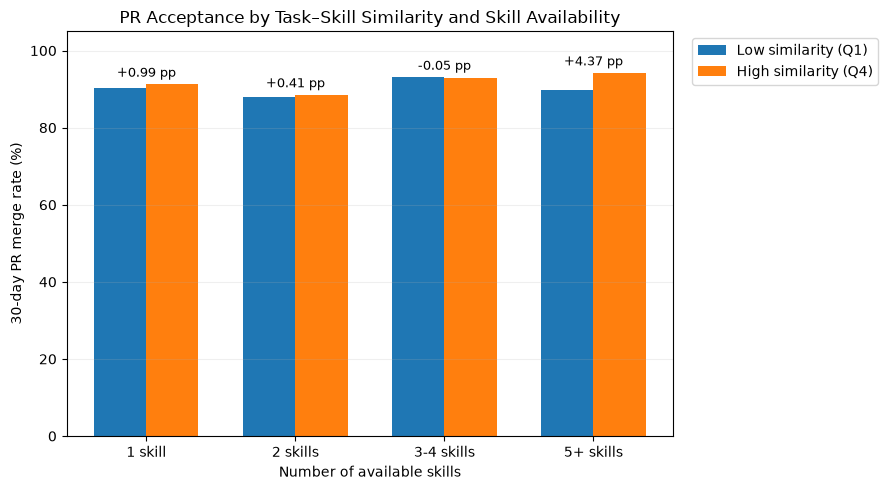

Figure saved: /Users/raselchowdhury/Desktop/Untitled/figures/rq2_skill_count_comparison.png


In [64]:

groups = ["1 skill", "2 skills", "3-4 skills", "5+ skills"]

plot_data = rate_comparison.reindex(groups)

x = np.arange(len(groups))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    x - width / 2,
    plot_data["Q1 - Lowest"],
    width,
    label="Low similarity (Q1)"
)

ax.bar(
    x + width / 2,
    plot_data["Q4 - Highest"],
    width,
    label="High similarity (Q4)"
)

for i, difference in enumerate(plot_data["difference_pp"]):
    ax.text(
        x[i],
        max(
            plot_data["Q1 - Lowest"].iloc[i],
            plot_data["Q4 - Highest"].iloc[i]
        ) + 2,
        f"{difference:+.2f} pp",
        ha="center",
        fontsize=9
    )

ax.set_xticks(x)
ax.set_xticklabels(groups)
ax.set_xlabel("Number of available skills")
ax.set_ylabel("30-day PR merge rate (%)")
ax.set_title("PR Acceptance by Task–Skill Similarity and Skill Availability")
ax.set_ylim(0, 105)
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
ax.grid(axis="y", alpha=0.2)

fig.tight_layout()

figure_path = FIG / "rq2_skill_count_comparison.png"
fig.savefig(figure_path, dpi=300, bbox_inches="tight")

plt.show()

print("Figure saved:", figure_path)



## 22. Export RQ2 Results

This section exports the task–skill similarity comparison by skill availability into a CSV file.

The exported table preserves the observed acceptance rates and differences between the lowest and highest similarity quartiles for reproducibility.

These comparisons are descriptive and should not be interpreted as causal effects.


In [65]:

PROCESSED.mkdir(parents=True, exist_ok=True)

output_path = PROCESSED / "rq2_skill_count_comparison.csv"

rate_comparison.to_csv(output_path, index=True)

saved_results = pd.read_csv(output_path)

print("RQ2 results exported successfully.")
print("File:", output_path)
print("Rows:", len(saved_results))

display(saved_results)


RQ2 results exported successfully.
File: /Users/raselchowdhury/Desktop/Untitled/data/processed/rq2_skill_count_comparison.csv
Rows: 4


,skill_count_group,Q1 - Lowest,Q4 - Highest,difference_pp,both_groups_at_least_30_prs
0,1 skill,90.227464,91.213389,0.985925,True
1,2 skills,88.073394,88.484848,0.411454,True
2,3-4 skills,93.023256,92.978208,-0.045048,True
3,5+ skills,89.781022,94.155019,4.373997,True



## 23. Verify Exported Summary

This section verifies the exported RQ2 results for completeness and internal consistency.

The checks confirm that all four skill availability groups are present, acceptance rates are valid, and reported differences agree with the underlying values.

Passing these checks confirms the integrity of the exported summary, not the causal validity of the findings.


In [66]:

assert output_path.exists()

final_results = pd.read_csv(output_path)

assert len(final_results) == 4
assert final_results["skill_count_group"].nunique() == 4
assert final_results.notna().all().all()

assert final_results["Q1 - Lowest"].between(0, 100).all()
assert final_results["Q4 - Highest"].between(0, 100).all()

assert np.allclose(
    final_results["Q4 - Highest"] - final_results["Q1 - Lowest"],
    final_results["difference_pp"],
    atol=1e-6
)

assert final_results["both_groups_at_least_30_prs"].all()

print("RQ2 final export verification: PASSED")
print("Exported groups:", len(final_results))
print("Missing values:", final_results.isna().sum().sum())
print("Validated file:", output_path.name)

display(final_results.round(2))


RQ2 final export verification: PASSED
Exported groups: 4
Missing values: 0
Validated file: rq2_skill_count_comparison.csv


,skill_count_group,Q1 - Lowest,Q4 - Highest,difference_pp,both_groups_at_least_30_prs
0,1 skill,90.23,91.21,0.99,True
1,2 skills,88.07,88.48,0.41,True
2,3-4 skills,93.02,92.98,-0.05,True
3,5+ skills,89.78,94.16,4.37,True


## 24. Audit Historical Skill Content

This section examines whether the agent skill content used for task–skill similarity analysis may have been modified after the corresponding pull request was created.

We compare each PR creation date with the recorded last modification date of its associated skills.

A later modification does not prove that the skill was unavailable or unused. However, it introduces uncertainty about whether the GitSkills snapshot accurately represents the skill content available when the PR was created.

We use this information to identify a conservative sample for sensitivity analysis.

In [67]:

history = con.execute("""
SELECT
    LOWER(repo_full_name) AS repo,
    path AS skill_path,
    file_sha AS skill_sha,
    MAX(
        TRY_CAST(
            REPLACE(last_commit_at, 'Z', '')
            AS TIMESTAMP
        )
    ) AS last_update_ts
FROM read_parquet(?)
WHERE filename = 'SKILL.md'
GROUP BY 1, 2, 3
""", [str(SKILLS)]).df()

audit = pr_skill_pairs.merge(
    history,
    on=["repo", "skill_path", "skill_sha"],
    how="left",
    validate="many_to_one"
)

future_updated = (
    audit["last_update_ts"] > audit["created_ts"]
)

unknown_dates = audit["last_update_ts"].isna()

print("Total PR-skill pairs:", len(audit))
print("Pairs updated after PR creation:", future_updated.sum())
print("Pairs with unknown last update:", unknown_dates.sum())
print(
    "PRs affected by later updates:",
    audit.loc[future_updated, "pr_id"].nunique()
)
print(
    "PRs with unknown skill update dates:",
    audit.loc[unknown_dates, "pr_id"].nunique()
)


Total PR-skill pairs: 27366
Pairs updated after PR creation: 13862
Pairs with unknown last update: 0
PRs affected by later updates: 4730
PRs with unknown skill update dates: 0


In [68]:

affected_prs = set(audit.loc[future_updated, "pr_id"])
all_prs = set(pr_skill_pairs["pr_id"])

unaffected_prs = all_prs - affected_prs

print("Total PRs:", len(all_prs))
print("PRs potentially affected:", len(affected_prs))
print("PRs without observed later skill updates:", len(unaffected_prs))
print("Retention rate:", round(100 * len(unaffected_prs) / len(all_prs), 2), "%")


Total PRs: 7371
PRs potentially affected: 4730
PRs without observed later skill updates: 2641
Retention rate: 35.83 %


In [69]:
conservative_pairs = pr_skill_pairs[
    pr_skill_pairs["pr_id"].isin(unaffected_prs)
].copy()

print("Original PRs:", pr_skill_pairs["pr_id"].nunique())
print("Conservative PRs:", conservative_pairs["pr_id"].nunique())
print("Conservative PR-skill pairs:", len(conservative_pairs))
print("Duplicates:", conservative_pairs.duplicated().sum())

assert conservative_pairs["pr_id"].nunique() == 2641
assert set(conservative_pairs["pr_id"]).isdisjoint(affected_prs)

print("Conservative sample validation: PASSED")

Original PRs: 7371
Conservative PRs: 2641
Conservative PR-skill pairs: 6979
Duplicates: 0
Conservative sample validation: PASSED


In [70]:
conservative_matches = best_matches[
    best_matches["pr_id"].isin(conservative_pairs["pr_id"])
].copy()

print("Conservative matches:", len(conservative_matches))
print("Unique PRs:", conservative_matches["pr_id"].nunique())
print("Duplicate PR IDs:", conservative_matches["pr_id"].duplicated().sum())

missing = set(conservative_pairs["pr_id"]) - set(conservative_matches["pr_id"])
print("Missing PRs:", len(missing))

assert conservative_matches["pr_id"].nunique() == 2641
assert len(missing) == 0

print("Similarity sample validation: PASSED")

Conservative matches: 2641
Unique PRs: 2641
Duplicate PR IDs: 0
Missing PRs: 0
Similarity sample validation: PASSED


In [71]:
import numpy as np

original = best_matches.set_index("pr_id")["similarity_score"]
conservative = conservative_matches.set_index("pr_id")["similarity_score"]

assert original.index.is_unique
assert conservative.index.is_unique
assert len(conservative) == 2641
assert conservative.index.isin(original.index).all()
assert conservative.notna().all()
assert conservative.between(0, 1).all()

expected = original.reindex(conservative.index)

assert np.allclose(conservative.to_numpy(), expected.to_numpy())

print("Conservative PRs:", len(conservative))
print("Missing similarity scores:", conservative.isna().sum())
print("Scores outside [0, 1]:", (~conservative.between(0, 1)).sum())
print("Similarity scores preserved: YES")

print("\nSimilarity distribution:")
print(conservative.describe(percentiles=[0.25, 0.5, 0.75, 0.9]).round(4).to_string())

print("\nValidation: PASSED")

Conservative PRs: 2641
Missing similarity scores: 0
Scores outside [0, 1]: 0
Similarity scores preserved: YES

Similarity distribution:
count    2641.0000
mean        0.0601
std         0.0548
min         0.0000
25%         0.0250
50%         0.0439
75%         0.0786
90%         0.1295
max         0.5143

Validation: PASSED


In [72]:
import pandas as pd
import numpy as np

sample_check = best_matches[
    ["pr_id", "similarity_score"]
].drop_duplicates("pr_id").copy()

retained_ids = set(conservative_matches["pr_id"])

sample_check["sample"] = np.where(
    sample_check["pr_id"].isin(retained_ids),
    "Retained",
    "Excluded"
)

summary = sample_check.groupby("sample").agg(
    prs=("pr_id", "count"),
    mean_similarity=("similarity_score", "mean"),
    median_similarity=("similarity_score", "median"),
    zero_scores=("similarity_score", lambda x: (x == 0).sum())
).reset_index()

summary["percentage"] = (
    100 * summary["prs"] / len(sample_check)
)

print("Original sample:", len(sample_check))
print("Retained PRs:", len(retained_ids))
print("\nSample comparison:")

display(summary.round(4))

assert len(sample_check) == 7371
assert summary["prs"].sum() == 7371

print("\nSample selection validation: PASSED")

Original sample: 7371
Retained PRs: 2641

Sample comparison:


,sample,prs,mean_similarity,median_similarity,zero_scores,percentage
0,Excluded,4730,0.0708,0.0514,21,64.1704
1,Retained,2641,0.0601,0.0439,71,35.8296



Sample selection validation: PASSED


In [73]:
pr_agents = pr_skill_pairs[
    ["pr_id", "agent"]
].drop_duplicates("pr_id")

agent_audit = sample_check[
    ["pr_id", "sample"]
].merge(
    pr_agents,
    on="pr_id",
    how="left",
    validate="one_to_one"
)

agent_summary = agent_audit.groupby(
    ["agent", "sample"]
).size().unstack(fill_value=0)

agent_summary["total"] = agent_summary.sum(axis=1)

agent_summary["retention_pct"] = (
    100 * agent_summary["Retained"]
    / agent_summary["total"]
)

display(agent_summary.round(2))

assert len(agent_audit) == 7371
assert agent_audit["agent"].notna().all()

print("Agent selection validation: PASSED")

sample,Excluded,Retained,total,retention_pct
agent,,,,
Claude_Code,4467,2332,6799,34.30
Copilot,154,192,346,55.49
Cursor,58,8,66,12.12
Google_Jules,7,36,43,83.72
OpenAI_Codex,44,73,117,62.39


Agent selection validation: PASSED


In [74]:
score_audit = agent_audit.merge(
    best_matches[["pr_id", "similarity_score"]],
    on="pr_id",
    how="left",
    validate="one_to_one"
)

score_summary = (
    score_audit.groupby(["agent", "sample"])
    .agg(
        prs=("pr_id", "size"),
        mean_similarity=("similarity_score", "mean"),
        median_similarity=("similarity_score", "median")
    )
    .reset_index()
)

display(score_summary.round(4))

assert len(score_audit) == 7371
assert score_audit["similarity_score"].notna().all()

print("Agent similarity selection audit: PASSED")

,agent,sample,prs,mean_similarity,median_similarity
0,Claude_Code,Excluded,4467,0.0721,0.0524
1,Claude_Code,Retained,2332,0.0592,0.0436
2,Copilot,Excluded,154,0.0597,0.0472
3,Copilot,Retained,192,0.0765,0.0587
4,Cursor,Excluded,58,0.0213,0.0143
5,Cursor,Retained,8,0.0275,0.0251
6,Google_Jules,Excluded,7,0.0207,0.0183
7,Google_Jules,Retained,36,0.0345,0.0298
8,OpenAI_Codex,Excluded,44,0.0477,0.0315
9,OpenAI_Codex,Retained,73,0.0592,0.0439


Agent similarity selection audit: PASSED


In [75]:
pr_outcomes = pr_skill_pairs[
    ["pr_id", "merged_30d"]
].drop_duplicates()

assert pr_outcomes["pr_id"].is_unique

selection_outcomes = score_audit.merge(
    pr_outcomes,
    on="pr_id",
    how="left",
    validate="one_to_one"
)

assert len(selection_outcomes) == 7371
assert selection_outcomes["merged_30d"].notna().all()

selection_comparison = (
    selection_outcomes.groupby(["agent", "sample"])
    .agg(
        prs=("pr_id", "size"),
        merged=("merged_30d", "sum"),
        mean_similarity=("similarity_score", "mean")
    )
    .reset_index()
)

selection_comparison["merge_rate_pct"] = (
    100 * selection_comparison["merged"] / selection_comparison["prs"]
)

display(selection_comparison.round(2))

print("Selection outcome audit: PASSED")

,agent,sample,prs,merged,mean_similarity,merge_rate_pct
0,Claude_Code,Excluded,4467,4171,0.07,93.37
1,Claude_Code,Retained,2332,2169,0.06,93.01
2,Copilot,Excluded,154,115,0.06,74.68
3,Copilot,Retained,192,134,0.08,69.79
4,Cursor,Excluded,58,38,0.02,65.52
5,Cursor,Retained,8,6,0.03,75.00
6,Google_Jules,Excluded,7,6,0.02,85.71
7,Google_Jules,Retained,36,15,0.03,41.67
8,OpenAI_Codex,Excluded,44,33,0.05,75.00
9,OpenAI_Codex,Retained,73,57,0.06,78.08


Selection outcome audit: PASSED


## 25. Historical-Content Sensitivity Analysis

This section evaluates whether the findings from RQ2 remain consistent when restricting the analysis to pull requests whose available skill content was not subsequently modified, according to the recorded GitSkills history.

We compare the original sample of 7,371 pull requests with the conservative sample of 2,641 pull requests.

The sensitivity analysis examines three aspects:

1. PR acceptance across task–skill similarity quartiles.
2. Differences within the same repository and coding agent.
3. The influence of the number of available skills.

We preserve the original similarity quartile boundaries to ensure that both samples are evaluated using the same classification.

**Limitations.** The conservative sample excludes a substantial proportion of the original observations and may introduce selection bias. The results remain observational and do not establish a causal relationship between skill relevance and PR acceptance.

In [76]:
conservative_rq2 = task_acceptance[
    task_acceptance["pr_id"].isin(conservative_matches["pr_id"])
].copy()

assert len(conservative_rq2) == 2641
assert conservative_rq2["pr_id"].is_unique
assert conservative_rq2["match_quartile"].notna().all()

original_rates = task_acceptance.groupby(
    "match_quartile",
    observed=True
).agg(
    original_prs=("pr_id", "count"),
    original_merged=("merged_30d", "sum")
).reset_index()

conservative_rates = conservative_rq2.groupby(
    "match_quartile",
    observed=True
).agg(
    conservative_prs=("pr_id", "count"),
    conservative_merged=("merged_30d", "sum"),
    repositories=("repo", "nunique")
).reset_index()

sensitivity_results = original_rates.merge(
    conservative_rates,
    on="match_quartile",
    how="left",
    validate="one_to_one"
)

sensitivity_results["original_rate_pct"] = (
    100 * sensitivity_results["original_merged"]
    / sensitivity_results["original_prs"]
)

sensitivity_results["conservative_rate_pct"] = (
    100 * sensitivity_results["conservative_merged"]
    / sensitivity_results["conservative_prs"]
)

sensitivity_results["change_pp"] = (
    sensitivity_results["conservative_rate_pct"]
    - sensitivity_results["original_rate_pct"]
)

sensitivity_results["retention_pct"] = (
    100 * sensitivity_results["conservative_prs"]
    / sensitivity_results["original_prs"]
)

print("Original PRs:", len(task_acceptance))
print("Conservative PRs:", len(conservative_rq2))

print("\nOriginal versus conservative acceptance:")
display(sensitivity_results.round(2))

assert sensitivity_results["conservative_prs"].sum() == 2641
assert sensitivity_results["conservative_rate_pct"].between(0, 100).all()

print("\nQuartile sensitivity verification: PASSED")

Original PRs: 7371
Conservative PRs: 2641

Original versus conservative acceptance:


,match_quartile,original_prs,original_merged,conservative_prs,conservative_merged,repositories,original_rate_pct,conservative_rate_pct,change_pp,retention_pct
0,Q1 - Lowest,1843,1666,836,756,118,90.40,90.43,0.03,45.36
1,Q2 - Low-Medium,1843,1695,611,551,116,91.97,90.18,-1.79,33.15
2,Q3 - High-Medium,1842,1676,637,559,107,90.99,87.76,-3.23,34.58
3,Q4 - Highest,1843,1707,557,515,110,92.62,92.46,-0.16,30.22



Quartile sensitivity verification: PASSED


In [77]:
extreme_conservative = conservative_rq2[
    conservative_rq2["match_quartile"].isin(
        ["Q1 - Lowest", "Q4 - Highest"]
    )
].copy()

group_summary = extreme_conservative.groupby(
    ["repo", "agent", "match_quartile"],
    observed=True
).agg(
    prs=("pr_id", "count"),
    merged=("merged_30d", "sum")
).reset_index()

low = group_summary[
    group_summary["match_quartile"] == "Q1 - Lowest"
][["repo", "agent", "prs", "merged"]].rename(
    columns={"prs": "q1_prs", "merged": "q1_merged"}
)

high = group_summary[
    group_summary["match_quartile"] == "Q4 - Highest"
][["repo", "agent", "prs", "merged"]].rename(
    columns={"prs": "q4_prs", "merged": "q4_merged"}
)

paired = low.merge(
    high,
    on=["repo", "agent"],
    how="inner",
    validate="one_to_one"
)

eligible = paired[
    (paired["q1_prs"] >= 3)
    & (paired["q4_prs"] >= 3)
].copy()

print("Conservative PRs:", len(conservative_rq2))
print("Comparable repository-agent groups:", len(eligible))
print("Comparable repositories:", eligible["repo"].nunique())

if len(eligible) > 0:

    eligible["difference_pp"] = 100 * (
        eligible["q4_merged"] / eligible["q4_prs"]
        - eligible["q1_merged"] / eligible["q1_prs"]
    )

    repository_differences = eligible.groupby(
        "repo"
    )["difference_pp"].mean()

    values = repository_differences.to_numpy()

    rng = np.random.default_rng(2027)

    bootstrap = rng.choice(
        values,
        size=(5000, len(values)),
        replace=True
    ).mean(axis=1)

    lower, upper = np.percentile(
        bootstrap,
        [2.5, 97.5]
    )

    print("\nOriginal mean difference:",
          round(repo_differences.mean(), 2), "pp")

    print("Conservative mean difference:",
          round(values.mean(), 2), "pp")

    print("95% bootstrap CI:",
          round(lower, 2), "to",
          round(upper, 2), "pp")

    print("Confidence interval includes zero:",
          bool(lower <= 0 <= upper))

    print("\nRepository-level directions:")
    print("Positive:", int((values > 0).sum()))
    print("Negative:", int((values < 0).sum()))
    print("Equal:", int((values == 0).sum()))

else:
    print("\nInsufficient comparable groups for this analysis.")

print("\nWithin-repository sensitivity assessment completed.")

Conservative PRs: 2641
Comparable repository-agent groups: 22
Comparable repositories: 22

Original mean difference: 0.38 pp
Conservative mean difference: 0.43 pp
95% bootstrap CI: -4.08 to 4.68 pp
Confidence interval includes zero: True

Repository-level directions:
Positive: 8
Negative: 5
Equal: 9

Within-repository sensitivity assessment completed.


In [78]:
conservative_skill_analysis = conservative_rq2[
    conservative_rq2["match_quartile"].isin(
        ["Q1 - Lowest", "Q4 - Highest"]
    )
].copy()

conservative_skill_analysis["skill_count_group"] = pd.cut(
    conservative_skill_analysis["available_skills_checked"],
    bins=[0, 1, 2, 4, np.inf],
    labels=["1 skill", "2 skills", "3-4 skills", "5+ skills"],
    include_lowest=True
)

conservative_skill_results = (
    conservative_skill_analysis.groupby(
        ["skill_count_group", "match_quartile"],
        observed=True
    )
    .agg(
        prs=("pr_id", "count"),
        repositories=("repo", "nunique"),
        merged=("merged_30d", "sum")
    )
    .reset_index()
)

conservative_skill_results["merge_rate_pct"] = (
    100 * conservative_skill_results["merged"]
    / conservative_skill_results["prs"]
)

rates = conservative_skill_results.pivot(
    index="skill_count_group",
    columns="match_quartile",
    values="merge_rate_pct"
)

counts = conservative_skill_results.pivot(
    index="skill_count_group",
    columns="match_quartile",
    values="prs"
)

rates["difference_pp"] = (
    rates["Q4 - Highest"]
    - rates["Q1 - Lowest"]
)

rates["q1_prs"] = counts["Q1 - Lowest"]
rates["q4_prs"] = counts["Q4 - Highest"]

rates["at_least_30_each"] = (
    (rates["q1_prs"] >= 30)
    & (rates["q4_prs"] >= 30)
)

print("Conservative acceptance by skill availability:")
display(rates.round(2))

print("\nOriginal comparison:")
display(rate_comparison.round(2))

assert conservative_skill_results["prs"].sum() == len(
    conservative_skill_analysis
)

print("\nSkill availability sensitivity verification: PASSED")

Conservative acceptance by skill availability:


match_quartile,Q1 - Lowest,Q4 - Highest,difference_pp,q1_prs,q4_prs,at_least_30_each
skill_count_group,,,,,,
1 skill,90.74,90.72,-0.02,659,194,True
2 skills,92.11,98.18,6.08,76,55,True
3-4 skills,85.92,95.20,9.28,71,125,True
5+ skills,90.00,90.71,0.71,30,183,True



Original comparison:


match_quartile,Q1 - Lowest,Q4 - Highest,difference_pp,both_groups_at_least_30_prs
skill_count_group,,,,
1 skill,90.23,91.21,0.99,True
2 skills,88.07,88.48,0.41,True
3-4 skills,93.02,92.98,-0.05,True
5+ skills,89.78,94.16,4.37,True



Skill availability sensitivity verification: PASSED


## 26. RQ2 — Synthesis and Interpretation

This section summarizes the findings for the three factors investigated in RQ2 and distinguishes descriptive associations from results that remain uncertain after additional checks.

### Task–Skill Similarity

In the original sample of 7,371 pull requests, the 30-day merge rate increased from 90.40% in the lowest similarity quartile to 92.62% in the highest quartile.

However, comparisons within the same repository and coding agent produced a much smaller average difference of 0.38 percentage points, with a 95% confidence interval that included zero.

Historical skill-content auditing also identified potential measurement uncertainty. After excluding PRs associated with skills modified after PR creation, 2,641 PRs remained. The conservative within-repository analysis showed a difference of 0.43 percentage points (95% CI: −4.08 to 4.68).

These findings suggest a positive descriptive association in the pooled sample, but do not establish a statistically conclusive relationship in the more controlled comparisons.

### Agent–Skill Compatibility

Observed acceptance rates differed across compatibility categories. However, these categories were unevenly distributed across coding agents, limiting meaningful comparisons.

Furthermore, documented support for a skill location does not demonstrate that the agent actually loaded or used the skill.

Therefore, the available evidence does not establish whether agent–skill compatibility changes the relationship between skill adoption and PR acceptance.

### Skill Provenance

Merge rates were relatively similar across the observed content-reuse categories. However, identical content hashes only provide evidence of shared content, not its original authorship or copying direction.

The limited number of repositories containing multiple reuse categories further restricts direct comparisons.

Consequently, the available data do not establish whether locally authored or reused skills are associated with different acceptance outcomes.

### Overall Interpretation

RQ2 identifies exploratory associations between skill characteristics and PR acceptance, particularly for task–skill similarity.

However, the findings are sensitive to repository and agent composition, historical skill-content uncertainty, and sample selection.

The analyses do not establish causal effects or demonstrate that these characteristics modify the effect of skill adoption. Answering that stronger question would require additional comparisons of pre-adoption and post-adoption outcomes across the relevant subgroups.

## 27. Test Whether Skill Content Reuse Moderates the RQ1 Association

This analysis connects the paired difference-in-differences results from RQ1 to the content-reuse characteristics of skills recorded at adoption.

We classify repositories using skills whose recorded first-commit dates are no later than the adoption date.

We compare the RQ1 estimates across content-reuse categories and calculate bootstrap confidence intervals.

Content reuse is measured using GitSkills snapshot hashes. It does not establish local authorship or historical content identity. Results remain exploratory.

In [79]:
rq2_did = pd.read_csv(
    PROCESSED / "rq1_paired_results.csv"
)[["pair_id", "did"]].copy()

rq2_initial_skills = skills_provenance[
    skills_provenance["skill_first_ts"]
    <= skills_provenance["adoption_ts"]
].copy()

rq2_initial_features = rq2_initial_skills.groupby(
    "pair_id"
).agg(
    initial_skills=("file_sha", "count"),
    shared_skills=(
        "content_reuse_category",
        lambda x: (x == "Shared identical content").sum()
    ),
    nonshared_skills=(
        "content_reuse_category",
        lambda x: (x == "No observed duplicate").sum()
    )
).reset_index()

rq2_effect_pairs = rq2_did.merge(
    rq2_initial_features,
    on="pair_id",
    how="left",
    validate="one_to_one"
)

rq2_effect_pairs["reuse_group"] = np.select(
    [
        (rq2_effect_pairs["shared_skills"] > 0)
        & (rq2_effect_pairs["nonshared_skills"] > 0),

        (rq2_effect_pairs["shared_skills"] > 0)
        & (rq2_effect_pairs["nonshared_skills"] == 0),

        (rq2_effect_pairs["shared_skills"] == 0)
        & (rq2_effect_pairs["nonshared_skills"] > 0)
    ],
    [
        "Mixed content",
        "Shared content only",
        "No observed duplicates only"
    ],
    default="Unclassified"
)

rng = np.random.default_rng(2027)
rq2_reuse_effects = []

for group, subset in rq2_effect_pairs.groupby("reuse_group"):

    values = subset["did"].dropna().to_numpy()
    n = len(values)

    if n >= 5:
        bootstrap = rng.choice(
            values,
            size=(5000, n),
            replace=True
        ).mean(axis=1)

        lower, upper = np.percentile(
            bootstrap, [2.5, 97.5]
        ) * 100
    else:
        lower, upper = np.nan, np.nan

    rq2_reuse_effects.append({
        "reuse_group": group,
        "pairs": n,
        "did_pp": values.mean() * 100 if n else np.nan,
        "ci_lower_pp": lower,
        "ci_upper_pp": upper,
        "limited_sample": n < 10
    })

rq2_reuse_effects = pd.DataFrame(rq2_reuse_effects)

print("Original RQ1 pairs:", len(rq2_did))
print("Pairs classified:", len(rq2_effect_pairs))
print("Initial skills:", len(rq2_initial_skills))

print("\nDiD by skill content reuse:")
display(rq2_reuse_effects.round(2))

assert len(rq2_effect_pairs) == len(rq2_did)
assert rq2_effect_pairs["pair_id"].is_unique
assert len(rq2_did) == 184

print("\nContent reuse heterogeneity analysis: PASSED")

Original RQ1 pairs: 184
Pairs classified: 184
Initial skills: 960

DiD by skill content reuse:


,reuse_group,pairs,did_pp,ci_lower_pp,ci_upper_pp,limited_sample
0,Mixed content,14,-4.86,-32.27,21.97,False
1,No observed duplicates only,104,-5.46,-13.36,1.82,False
2,Shared content only,66,-3.97,-15.05,6.81,False



Content reuse heterogeneity analysis: PASSED


## 28. Agent–Skill Compatibility and Adoption Effects

This section examines whether the RQ1 difference-in-differences estimates vary according to documented agent–skill compatibility at adoption.

We identify AI coding agents active during the 30 days before adoption and compare their documented skill-directory support with the skills recorded at adoption.

This is a repository-level proxy for potential compatibility. It does not establish that an agent loaded or used a skill.

We report subgroup estimates and assess whether sufficient observations exist for meaningful comparisons.

In [80]:
rq2_pre_agents = con.execute("""
WITH pre_prs AS (
    SELECT
        t.pair_id,
        p.agent,
        TRY_CAST(
            REPLACE(p.created_at, 'Z', '')
            AS TIMESTAMP
        ) AS created_ts,
        t.adoption_ts
    FROM read_parquet(?) p
    JOIN rq2_treated_repos t
      ON LOWER(REPLACE(
          p.repo_url,
          'https://api.github.com/repos/',
          ''
      )) = t.repo
)
SELECT
    pair_id,
    agent,
    COUNT(*) AS pre_prs
FROM pre_prs
WHERE created_ts >= adoption_ts - INTERVAL 30 DAY
  AND created_ts < adoption_ts
GROUP BY pair_id, agent
""", [str(PRS)]).df()

rq2_compat_pairs = rq2_pre_agents.merge(
    rq2_initial_skills[
        ["pair_id", "path"]
    ].drop_duplicates(),
    on="pair_id",
    how="inner"
).merge(
    treated_repos[
        ["pair_id", "adoption_ts"]
    ],
    on="pair_id",
    how="left",
    validate="many_to_one"
)

rq2_compat_pairs["path_norm"] = (
    rq2_compat_pairs["path"]
    .str.replace("\\", "/", regex=False)
    .str.replace(r"^\./", "", regex=True)
    .str.lower()
)

rq2_compat_pairs["documented"] = False
rq2_compat_pairs["unknown_start"] = False

rq2_reference = compatibility.copy()
rq2_reference["since_ts"] = pd.to_datetime(
    rq2_reference["since"],
    errors="coerce"
)

for ref in rq2_reference.itertuples(index=False):

    if ref.status != "confirmed":
        continue

    location = str(ref.location).lower()

    matching = (
        rq2_compat_pairs["agent"].eq(ref.agent)
        & rq2_compat_pairs["path_norm"].str.startswith(
            location + "/"
        )
    )

    if ref.agent == "Claude_Code" and location == ".claude/skills":
        matching = (
            rq2_compat_pairs["agent"].eq(ref.agent)
            & (
                rq2_compat_pairs["path_norm"].str.startswith(
                    ".claude/skills/"
                )
                | rq2_compat_pairs["path_norm"].str.contains(
                    "/.claude/skills/",
                    regex=False
                )
            )
        )

    if pd.notna(ref.since_ts):
        matching = matching & (
            rq2_compat_pairs["adoption_ts"] >= ref.since_ts
        )

        rq2_compat_pairs.loc[
            matching, "documented"
        ] = True

    else:
        rq2_compat_pairs.loc[
            matching, "unknown_start"
        ] = True

rq2_compat_by_pair = rq2_compat_pairs.groupby(
    "pair_id"
).agg(
    documented=("documented", "any"),
    unknown_start=("unknown_start", "any"),
    pre_agents=("agent", "nunique")
).reset_index()

rq2_compat_effects = rq2_did.merge(
    rq2_compat_by_pair,
    on="pair_id",
    how="left",
    validate="one_to_one"
)

rq2_compat_effects["compat_group"] = np.select(
    [
        rq2_compat_effects["documented"].eq(True),
        rq2_compat_effects["unknown_start"].eq(True),
        rq2_compat_effects["pre_agents"].notna()
    ],
    [
        "Documented by adoption",
        "Support start unknown",
        "Not documented"
    ],
    default="No eligible pre-adoption data"
)

rng = np.random.default_rng(2027)
rq2_compat_results = []

for group, subset in rq2_compat_effects.groupby("compat_group"):

    values = subset["did"].dropna().to_numpy()
    n = len(values)

    if n >= 5:
        bootstrap = rng.choice(
            values,
            size=(5000, n),
            replace=True
        ).mean(axis=1)

        lower, upper = (
            np.percentile(bootstrap, [2.5, 97.5]) * 100
        )
    else:
        lower, upper = np.nan, np.nan

    rq2_compat_results.append({
        "compatibility": group,
        "pairs": n,
        "did_pp": values.mean() * 100 if n else np.nan,
        "ci_lower_pp": lower,
        "ci_upper_pp": upper
    })

rq2_compat_results = pd.DataFrame(rq2_compat_results)

print("RQ1 complete pairs:", len(rq2_did))
print("Pre-adoption agent records:", len(rq2_pre_agents))
print("Agent-skill combinations:", len(rq2_compat_pairs))

print("\nDiD by agent-skill compatibility:")
display(rq2_compat_results.round(2))

print("\nGroups with at least 10 pairs:",
      int((rq2_compat_results["pairs"] >= 10).sum()))

assert len(rq2_compat_effects) == 184
assert rq2_compat_effects["pair_id"].is_unique
assert rq2_compat_results["pairs"].sum() == 184

print("\nCompatibility heterogeneity analysis: PASSED")

RQ1 complete pairs: 184
Pre-adoption agent records: 432
Agent-skill combinations: 916

DiD by agent-skill compatibility:


,compatibility,pairs,did_pp,ci_lower_pp,ci_upper_pp
0,Documented by adoption,171,-5.41,-12.03,0.88
1,Not documented,12,0.21,-20.22,22.06
2,Support start unknown,1,25.34,NaN,NaN



Groups with at least 10 pairs: 2

Compatibility heterogeneity analysis: PASSED


## 29. Baseline Task–Skill Alignment and Adoption Effects

We examine whether the RQ1 difference-in-differences estimates vary according to the alignment between pre-adoption PR tasks and the skills recorded at adoption.

For each treated repository, we calculate textual similarity between PRs created during the 30 days before adoption and the skills recorded as introduced by the adoption date.

We then compare repository-level DiD estimates across lower- and higher-alignment groups.

This retrospective measure uses GitSkills snapshot content and does not establish that these skills were available or used before adoption. Results remain exploratory.

In [82]:
rq2_baseline_pairs = rq2_did[["pair_id"]].merge(
    treated_repos[["pair_id", "repo", "adoption_ts"]],
    on="pair_id",
    validate="one_to_one"
)

con.register("rq2_baseline_pairs", rq2_baseline_pairs)

rq2_pre_ids = con.execute("""
SELECT
    t.pair_id,
    p.id AS pr_id
FROM read_parquet(?) p
JOIN rq2_baseline_pairs t
    ON LOWER(REPLACE(
        p.repo_url,
        'https://api.github.com/repos/',
        ''
    )) = t.repo
WHERE TRY_CAST(
    REPLACE(p.created_at, 'Z', '')
    AS TIMESTAMP
) >= t.adoption_ts - INTERVAL 30 DAY
AND TRY_CAST(
    REPLACE(p.created_at, 'Z', '')
    AS TIMESTAMP
) < t.adoption_ts
""", [str(PRS)]).df().drop_duplicates()

con.register(
    "rq2_baseline_pr_ids",
    rq2_pre_ids[["pr_id"]].drop_duplicates()
)

rq2_pre_text = con.execute("""
SELECT
    p.id AS pr_id,
    p.title,
    p.body
FROM read_parquet(?) p
SEMI JOIN rq2_baseline_pr_ids ids
    ON p.id = ids.pr_id
""", [aidev_url]).df()

rq2_pre_docs = rq2_pre_ids.merge(
    rq2_pre_text,
    on="pr_id",
    how="inner",
    validate="many_to_one"
)

rq2_pre_docs["task_text"] = (
    rq2_pre_docs["title"].fillna("").str.slice(0, 250)
    + " "
    + rq2_pre_docs["body"].fillna("").str.slice(0, 2500)
).str.strip()

rq2_pre_docs["pr_idx"] = np.arange(len(rq2_pre_docs))

rq2_pre_vectors = vectorizer.transform(
    rq2_pre_docs["task_text"]
)

rq2_initial_index = rq2_initial_skills[
    ["pair_id", "repo", "path", "file_sha"]
].drop_duplicates().merge(
    skill_docs[
        ["repo", "path", "file_sha", "skill_idx"]
    ],
    on=["repo", "path", "file_sha"],
    how="inner",
    validate="many_to_one"
)

rq2_baseline_combinations = rq2_pre_docs[
    ["pair_id", "pr_id", "pr_idx"]
].merge(
    rq2_initial_index[["pair_id", "skill_idx"]],
    on="pair_id"
)

pr_idx = rq2_baseline_combinations["pr_idx"].to_numpy(dtype=int)
skill_idx = rq2_baseline_combinations["skill_idx"].to_numpy(dtype=int)

rq2_baseline_combinations["similarity"] = np.asarray(
    rq2_pre_vectors[pr_idx]
    .multiply(skill_vectors[skill_idx])
    .sum(axis=1)
).ravel()

rq2_baseline_best = (
    rq2_baseline_combinations.groupby(
        ["pair_id", "pr_id"]
    )["similarity"].max().reset_index()
)

rq2_baseline_summary = (
    rq2_baseline_best.groupby("pair_id")
    .agg(
        baseline_similarity=("similarity", "mean"),
        pre_prs=("pr_id", "count")
    )
    .reset_index()
)

rq2_alignment_effects = rq2_did.merge(
    rq2_baseline_summary,
    on="pair_id",
    how="left",
    validate="one_to_one"
)

print("RQ1 complete pairs:", len(rq2_did))
print("Pre-adoption PRs:", len(rq2_pre_docs))
print("Repositories with baseline similarity:",
      rq2_alignment_effects["baseline_similarity"].notna().sum())

assert rq2_alignment_effects["baseline_similarity"].notna().all()

median = rq2_alignment_effects["baseline_similarity"].median()

rq2_alignment_effects["alignment_group"] = np.where(
    rq2_alignment_effects["baseline_similarity"] > median,
    "Higher alignment",
    "Lower alignment"
)

rng = np.random.default_rng(2027)
rq2_alignment_results = []

for group, subset in rq2_alignment_effects.groupby("alignment_group"):

    values = subset["did"].to_numpy()
    n = len(values)

    bootstrap = rng.choice(
        values,
        size=(5000, n),
        replace=True
    ).mean(axis=1)

    lower, upper = np.percentile(
        bootstrap, [2.5, 97.5]
    ) * 100

    rq2_alignment_results.append({
        "alignment_group": group,
        "pairs": n,
        "baseline_similarity": subset["baseline_similarity"].mean(),
        "did_pp": values.mean() * 100,
        "ci_lower_pp": lower,
        "ci_upper_pp": upper
    })

rq2_alignment_results = pd.DataFrame(rq2_alignment_results)

print("\nDiD by baseline task-skill alignment:")
display(rq2_alignment_results.round(4))

low_values = rq2_alignment_effects.loc[
    rq2_alignment_effects["alignment_group"] == "Lower alignment",
    "did"
].to_numpy()

high_values = rq2_alignment_effects.loc[
    rq2_alignment_effects["alignment_group"] == "Higher alignment",
    "did"
].to_numpy()

difference_bootstrap = (
    rng.choice(
        high_values,
        size=(5000, len(high_values)),
        replace=True
    ).mean(axis=1)
    -
    rng.choice(
        low_values,
        size=(5000, len(low_values)),
        replace=True
    ).mean(axis=1)
)

print("\nDifference between higher and lower alignment DiD:")
print(round((high_values.mean() - low_values.mean()) * 100, 2), "pp")

print("95% bootstrap CI:",
      np.round(np.percentile(difference_bootstrap, [2.5, 97.5]) * 100, 2))

assert len(rq2_alignment_effects) == 184
assert rq2_alignment_effects["pair_id"].is_unique

print("\nBaseline alignment heterogeneity analysis: PASSED")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

RQ1 complete pairs: 184
Pre-adoption PRs: 5127
Repositories with baseline similarity: 184

DiD by baseline task-skill alignment:


,alignment_group,pairs,baseline_similarity,did_pp,ci_lower_pp,ci_upper_pp
0,Higher alignment,92,0.1175,-3.6347,-12.1943,4.8797
1,Lower alignment,92,0.0359,-6.1254,-15.0780,2.6236



Difference between higher and lower alignment DiD:
2.49 pp
95% bootstrap CI: [-10.1   15.26]

Baseline alignment heterogeneity analysis: PASSED


## 30. Final RQ2 Heterogeneity Validation

This section validates the repository-level heterogeneity analyses against the 184 complete RQ1 matched pairs.

We examine task–skill alignment, documented agent–skill compatibility, and skill content reuse. We additionally calculate bootstrap contrasts between subgroups with sufficient observations.

All estimates remain observational. Historical skill content and actual skill usage are not fully observable, and content reuse does not establish skill authorship.

In [83]:
from itertools import combinations

PROCESSED.mkdir(parents=True, exist_ok=True)

final_rq2 = rq2_did[["pair_id", "did"]].copy()

for source, column in [
    (rq2_effect_pairs, "reuse_group"),
    (rq2_compat_effects, "compat_group"),
    (rq2_alignment_effects, "alignment_group")
]:
    final_rq2 = final_rq2.merge(
        source[["pair_id", column]],
        on="pair_id",
        how="left",
        validate="one_to_one"
    )

assert len(final_rq2) == 184
assert final_rq2["pair_id"].is_unique
assert final_rq2[
    ["did", "reuse_group", "compat_group", "alignment_group"]
].notna().all().all()

rng = np.random.default_rng(2027)
contrasts = []

for dimension, column in [
    ("Content reuse", "reuse_group"),
    ("Agent compatibility", "compat_group"),
    ("Task alignment", "alignment_group")
]:
    groups = {
        group: frame["did"].to_numpy()
        for group, frame in final_rq2.groupby(column)
        if len(frame) >= 10
    }

    for (name_a, a), (name_b, b) in combinations(groups.items(), 2):
        boot_a = rng.choice(
            a, size=(5000, len(a)), replace=True
        ).mean(axis=1)

        boot_b = rng.choice(
            b, size=(5000, len(b)), replace=True
        ).mean(axis=1)

        lower, upper = np.percentile(
            (boot_a - boot_b) * 100,
            [2.5, 97.5]
        )

        contrasts.append({
            "dimension": dimension,
            "group_a": name_a,
            "group_b": name_b,
            "pairs_a": len(a),
            "pairs_b": len(b),
            "difference_pp": (a.mean() - b.mean()) * 100,
            "ci_lower_pp": lower,
            "ci_upper_pp": upper,
            "ci_includes_zero": lower <= 0 <= upper
        })

rq2_final_contrasts = pd.DataFrame(contrasts)

print("Final RQ2 sample:", len(final_rq2))
print("Overall DiD:", round(final_rq2["did"].mean() * 100, 2), "pp")

print("\nHeterogeneity comparisons:")
display(rq2_final_contrasts.round(2))

final_rq2.to_csv(
    PROCESSED / "rq2_heterogeneity_pairs.csv",
    index=False
)

rq2_final_contrasts.to_csv(
    PROCESSED / "rq2_heterogeneity_contrasts.csv",
    index=False
)

rq2_reuse_effects.to_csv(
    PROCESSED / "rq2_did_by_reuse.csv",
    index=False
)

rq2_compat_results.to_csv(
    PROCESSED / "rq2_did_by_compatibility.csv",
    index=False
)

rq2_alignment_results.to_csv(
    PROCESSED / "rq2_did_by_alignment.csv",
    index=False
)

assert len(rq2_final_contrasts) >= 3

print("\nFINAL RQ2 VALIDATION: PASSED")
print("Five CSV files exported.")

Final RQ2 sample: 184
Overall DiD: -4.88 pp

Heterogeneity comparisons:


,dimension,group_a,group_b,pairs_a,pairs_b,difference_pp,ci_lower_pp,ci_upper_pp,ci_includes_zero
0,Content reuse,Mixed content,No observed duplicates only,14,104,0.60,-27.23,28.31,True
1,Content reuse,Mixed content,Shared content only,14,66,-0.88,-29.87,28.63,True
2,Content reuse,No observed duplicates only,Shared content only,104,66,-1.49,-14.55,11.45,True
3,Agent compatibility,Documented by adoption,Not documented,171,12,-5.62,-28.15,16.62,True
4,Task alignment,Higher alignment,Lower alignment,92,92,2.49,-9.98,15.26,True



FINAL RQ2 VALIDATION: PASSED
Five CSV files exported.


## 31. Final RQ2 Conclusion

We examined whether the association between agent skill adoption and PR acceptance varies with task–skill alignment, documented agent–skill compatibility, and skill content reuse.

The heterogeneity analysis used the 184 complete matched pairs from RQ1. All five subgroup contrasts had 95% bootstrap confidence intervals that included zero.

We therefore found no statistically conclusive evidence that these characteristics modify the estimated adoption association.

The results remain exploratory due to sample size, unobserved confounding, historical skill-content uncertainty, and limitations in measuring actual skill usage and provenance.